<h2> Eastern Analysis</h2>

I need the daily generation data or daily hydrological data from different hydro substation for a more detail analysis and perfect analysis. use power market updated kernal

In [103]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import geopandas as gpd
#from shapely.ops import nearest_points
from scipy.optimize import curve_fit
#import shapely

from Network_Plot import check_line_loading

plt.rcParams.update({
        "font.weight": "bold",  # bold fonts
        "font.size":10,
        "lines.linewidth": 2,   # thick lines
        "grid.color": "0.5",    # gray gridlines
        "grid.linewidth": 0.5,  # thin gridlines
        "savefig.dpi": 300,     # higher resolution output.
        "axes.labelsize" : 15
    })

fig_size = (20,8)


#from Network_Plot import plot_network_flow

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [104]:
Cost_Scale = 1000000

### Hydropower Cost Analysis

### Cost and Revenue Generation

[Capex] Linear Fit: Cost = 210.804 * Capacity + -337.378
Mean Revenue per MW:  32.72368605805951
[Revenue] Linear Fit: Revenue = 28.667 * Capacity + 41.293


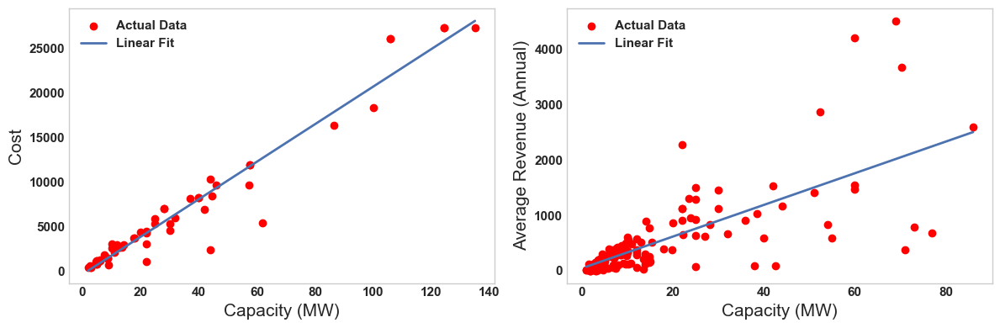

In [105]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ── Linear model (shared) ──────────────────────────────────────────────────────
def linear_model(x, a, b):
    return a * x + b

# ── Load data ──────────────────────────────────────────────────────────────────
hydro_cost = pd.read_excel('Data/Hydro_Transmission_Cost.xlsx', sheet_name='Capex')
revenue_royalty = pd.read_excel('Data/Hydro_Transmission_Cost.xlsx', sheet_name='Revenue_From_Royalty')
revenue_royalty = revenue_royalty.query('Installed_Capacity < 100000')

# ── Panel 1 data: Hydropower Capex vs Capacity ────────────────────────────────
x1 = hydro_cost['Capacity']
y1 = hydro_cost['Total Cost']/Cost_Scale

hydro_params_linear, _ = curve_fit(linear_model, x1, y1)
a1, b1 = hydro_params_linear
Hydro_Cost_per_MW = a1*Cost_Scale
print(f"[Capex] Linear Fit: Cost = {a1:.3f} * Capacity + {b1:.3f}")



x1_fit = np.linspace(min(x1), max(x1), 100)

# ── Panel 2 data: Revenue per MW vs Capacity ───────────────────────────────────
x2 = revenue_royalty['Installed_Capacity'] / 1000
y2 = revenue_royalty['Average Revenue'] / Cost_Scale
ratio = y2 / x2
print('Mean Revenue per MW: ', ratio.mean())

params_linear, _ = curve_fit(linear_model, x2, y2)
a2, b2 = params_linear
print(f"[Revenue] Linear Fit: Revenue = {a2:.3f} * Capacity + {b2:.3f}")

x2_fit = np.linspace(min(x2), max(x2), 100)

# ── Plot: 1 row, 2 columns ──────────────────────────────────────────────────────
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

# Panel 1: Hydropower Cost
ax[0].scatter(x1, y1, color='red', label='Actual Data')
ax[0].plot(x1_fit, linear_model(x1_fit, *hydro_params_linear), label='Linear Fit')
ax[0].set_xlabel("Capacity (MW)")
ax[0].set_ylabel("Cost")

ax[0].legend()
ax[0].grid()

# Panel 2: Revenue from Royalty
ax[1].scatter(x2, y2, color='red', label='Actual Data')
ax[1].plot(x2_fit, linear_model(x2_fit, *params_linear), label='Linear Fit')
ax[1].set_xlabel("Capacity (MW)")
ax[1].set_ylabel("Average Revenue (Annual)")

ax[1].legend()
ax[1].grid()

plt.tight_layout()
plt.show()

In [106]:
Hydro_Cost_per_MW

np.float64(210803649.49552768)

Linear Fit: Cost = 23.517 * Capacity + 21.152


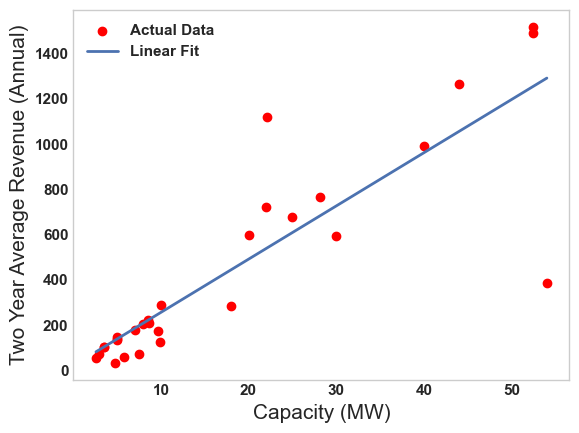

In [107]:
hydro_cf = pd.read_excel('Data/Hydro_Transmission_Cost.xlsx',sheet_name='Study')


x= hydro_cf['MW']
y = hydro_cf['Average']

# Linear model
def generator_cost_model(x, a, b):
    return a * x + b

params_linear, _ = curve_fit(generator_cost_model, x, y)

a, b = params_linear
print(f"Linear Fit: Cost = {a:.3f} * Capacity + {b:.3f}")
# Generate smooth curve
x_fit = np.linspace(min(x), max(x), 100)

plt.scatter(x, y, color='red', label='Actual Data')

# Linear curve
plt.plot(x_fit, generator_cost_model(x_fit, *params_linear), label='Linear Fit')



plt.xlabel("Capacity (MW)")
plt.ylabel("Two Year Average Revenue (Annual)")
plt.legend()
plt.grid()

plt.show()

### Capacity Factor

Linear Fit: Cost = 0.002 * Capacity + 0.527


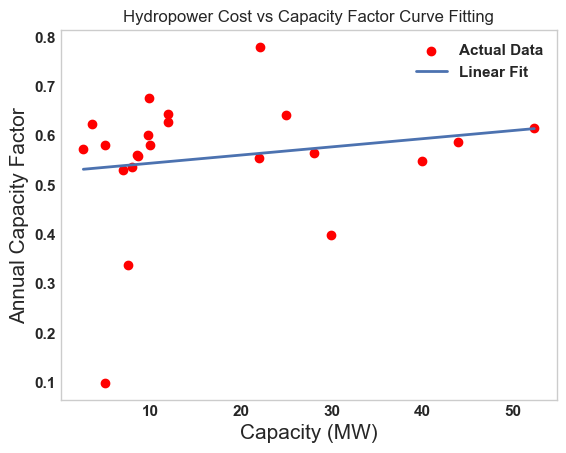

In [108]:
hydro_cf = pd.read_excel('Data/Hydro_Transmission_Cost.xlsx',sheet_name='Financial')
# Independent and dependent variables
y= hydro_cf['Capacity Factor']
x = hydro_cf['Installed Capacity']
params_linear, _ = curve_fit(generator_cost_model, x, y)

a, b = params_linear
print(f"Linear Fit: Cost = {a:.3f} * Capacity + {b:.3f}")
# Generate smooth curve
x_fit = np.linspace(min(x), max(x), 100)

plt.scatter(x, y, color='red', label='Actual Data')

# Linear curve
plt.plot(x_fit, generator_cost_model(x_fit, *params_linear), label='Linear Fit')



plt.xlabel("Capacity (MW)")
plt.ylabel("Annual Capacity Factor")
plt.title("Hydropower Cost vs Capacity Factor Curve Fitting")
plt.legend()
plt.grid()

plt.show()

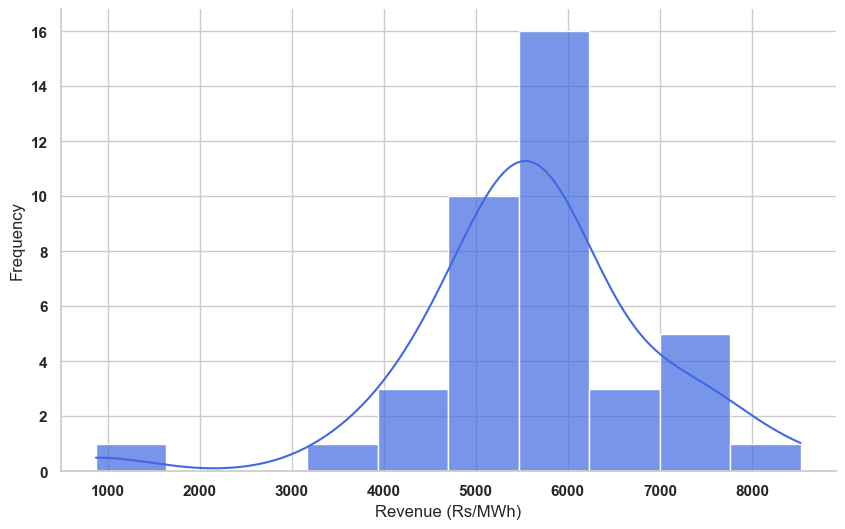

In [109]:
import seaborn as sns

revenue_per_mwh =np.concatenate((hydro_cf['Unit Cost 2080/81'],hydro_cf['Unit Cost 2081/82']))
# 2. Set the aesthetic style
sns.set_theme(style="whitegrid") # Use a clean grid background

# 3. Create the histogram
plt.figure(figsize=(10, 6))
plot = sns.histplot(
    revenue_per_mwh, 
    kde=True,              # Adds a smooth density curve
    color="royalblue",      # Set a professional bar color
    bins=10,               # Number of intervals
    edgecolor="white",     # White borders for better separation
    alpha=0.7              # Slight transparency for a modern look
)

# 4. Add titles and labels for clarity
plt.xlabel("Revenue (Rs/MWh)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

# 5. Fine-tune axes (optional)
sns.despine() # Remove the top and right spines for a cleaner look

# 6. Display the plot
plt.show()

### Hydrological Characteristics

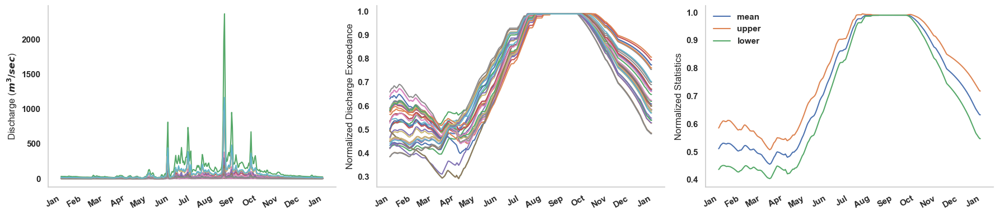

In [110]:
from Discharge_Data import Discharge_P_MAX_PU

hydrology_df = Discharge_P_MAX_PU()
snapshots = hydrology_df.index

In [111]:
hydrology_df

,mean,upper,lower
Snapshot,,,
2020-01-01 00:00:00,0.511100,0.585383,0.436818
2020-01-01 01:00:00,0.511229,0.585549,0.436910
2020-01-01 02:00:00,0.511358,0.585715,0.437001
2020-01-01 03:00:00,0.511487,0.585880,0.437093
2020-01-01 04:00:00,0.511616,0.586047,0.437185
...,...,...,...
2020-12-30 19:00:00,0.632656,0.718045,0.547267
2020-12-30 20:00:00,0.632656,0.718045,0.547267
2020-12-30 21:00:00,0.632656,0.718045,0.547267


In [112]:
p_max_pu_mean,p_max_pu_upper,p_max_pu_lower = hydrology_df.values.T

#### Loading Data

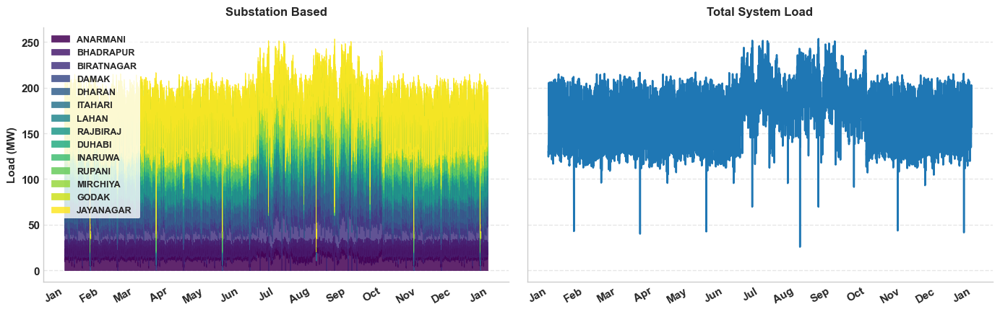

In [176]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ── Load and Prepare Data ────────────────────────────────────────────────────
Load_Data = pd.read_csv('Data/Loading_Data.csv')
Load_Data['Snapshot'] = pd.to_datetime(Load_Data['Snapshot'])
Load_Data = Load_Data.set_index('Snapshot')

# Set clean modern style
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(14, 4.5), sharey=True)

# ── 1. Component Breakdown (Stacked Area) ────────────────────────────────────
Load_Data.plot.area(
    ax=ax[0], 
    x_compat=True, 
    colormap="viridis", 
    alpha=0.85, 
    linewidth=0.5
)
ax[0].set_title("Substation Based", fontsize=12, fontweight="bold", pad=12)
ax[0].set_ylabel("Load (MW)", fontsize=11, fontweight="bold")
ax[0].legend(loc="upper left", frameon=True, facecolor="white", edgecolor="none", fontsize=9)

# ── 2. Total System Load (Line) ──────────────────────────────────────────────
total_load = Load_Data.sum(axis=1)
total_load.plot(
    ax=ax[1], 
    x_compat=True, 
    color="#1f77b4", 
    linewidth=1.8
)
ax[1].set_title("Total System Load", fontsize=12, fontweight="bold", pad=12)

# ── Common Axis Formatting ───────────────────────────────────────────────────
for i, a in enumerate(ax):
    a.xaxis.set_major_locator(mdates.MonthLocator())
    a.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    a.set_xlabel("")
    
    # Subtle horizontal grid for readability, no vertical grid
    a.grid(True, axis='y', linestyle='--', alpha=0.5)
    a.grid(False, axis='x')
    
    # Minimalist spine cleanup
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
    
    # Clean up redundant y-label on the right subplot
    if i == 1:
        a.set_ylabel("")

plt.tight_layout()
plt.savefig("Images/Load_Profile.png", dpi=300, bbox_inches="tight")
plt.show()

### Adding Timeseries Data in Standard Form

In [114]:
snapshot_df = pd.DataFrame({
    'Snapshot': snapshots
})

with pd.ExcelWriter('Data/Data_File_Year.xlsx', engine='openpyxl', mode='a', if_sheet_exists='replace') as writer:
    snapshot_df.to_excel(writer, sheet_name='snapshots', index=False)

with pd.ExcelWriter('Data/Data_File_Year.xlsx', engine='openpyxl', mode='a', if_sheet_exists='replace') as writer:
    Load_Data.abs().to_excel(writer, sheet_name='loads-p_set', index=True)

with pd.ExcelWriter('Data/Data_File_Year.xlsx', engine='openpyxl', mode='a', if_sheet_exists='replace') as writer:
    hydrology_df.to_excel(writer, sheet_name='p_max_pu', index=True)

### IEX Analysis

In [115]:
from IEX import get_IEX_data, IEX_data

df_MCP = get_IEX_data()

Processing: Data/IEX/IEX_data_2023.xlsx
Processing: Data/IEX/IEX_data_2024.xlsx
Processing: Data/IEX/IEX_data_2025.xlsx


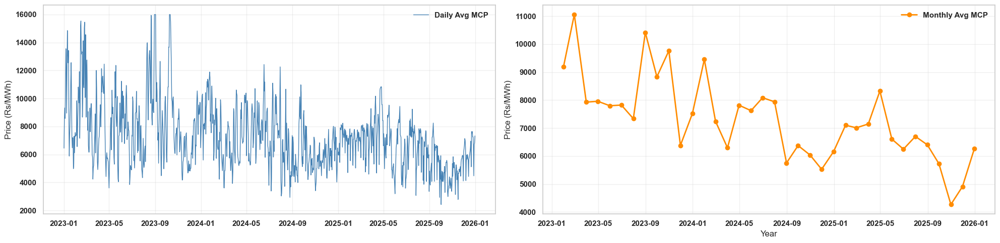

In [116]:
df_MCP = df_MCP[['Timestamp', 'MCP (Rs/MWh) *']]
df_MCP = df_MCP.set_index(['Timestamp'])
df_MCP = 1.6*df_MCP

daily_mcp = df_MCP['MCP (Rs/MWh) *'].resample('D').mean()
# Monthly Average Price (to see year-over-year seasonality)
monthly_mcp = df_MCP['MCP (Rs/MWh) *'].resample('ME').mean()
# Monthly Average Price (to see year-over-year seasonality)
# 3. Plotting
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20,5), sharex=False)

# --- Top Plot: Daily Average ---
ax1.plot(daily_mcp.index, daily_mcp.values, color='steelblue', linewidth=1, label='Daily Avg MCP')
ax1.set_ylabel('Price (Rs/MWh)')
ax1.grid(True, alpha=0.3)
ax1.legend()

# --- Bottom Plot: Monthly Average ---
ax2.plot(monthly_mcp.index, monthly_mcp.values, color='darkorange', marker='o', linewidth=2, label='Monthly Avg MCP')
ax2.set_ylabel('Price (Rs/MWh)')
ax2.set_xlabel('Year')
ax2.grid(True, alpha=0.3)
ax2.legend()

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

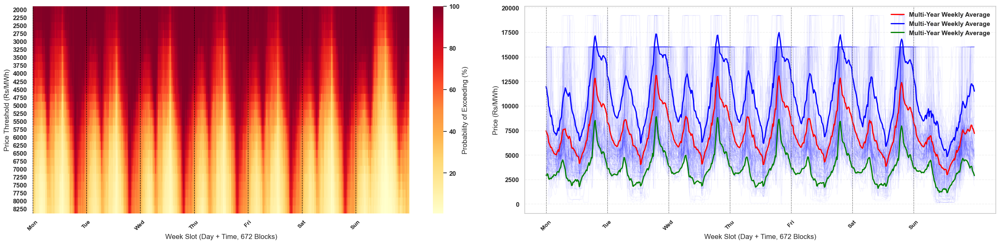

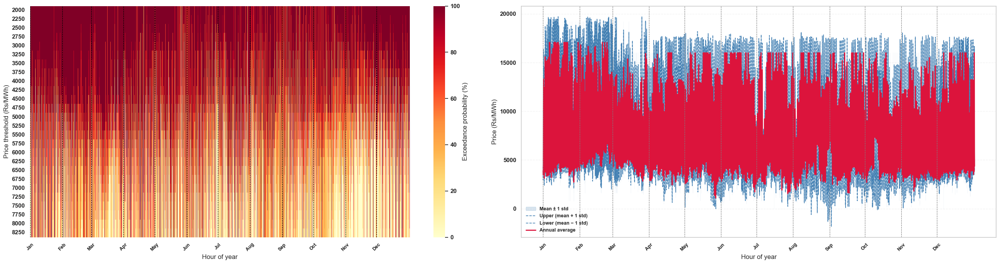

In [117]:
IEX_mean,IEX_upper,IEX_lower = IEX_data(df_MCP,snapshot_df)

### Transmission Line Cost

In [118]:
line_sub_cost = pd.read_excel('Data/Hydro_Transmission_Cost.xlsx',sheet_name='Tranmission Cost Summary')
line_sub_cost = line_sub_cost.to_dict()
line_sub_cost

{'Type': {0: 'Cost'},
 132: {0: 224010.17868471434},
 220: {0: 130138.84158396695},
 400: {0: 36267.504483219556},
 'Transformer': {0: 8928571.42857143}}

### Building Base Network


In [119]:
from Build_Network import Network_Base
from Scenario import Scenario_Analysis
load_growth_factor = 4

base_n = Scenario_Analysis(Network_Base(IEX_mean,Cost_Scale),Hydro_Cost_per_MW,line_sub_cost,load_growth_factor,Cost_Scale=Cost_Scale)

DataFrame: 'buses' with 45 rows.
DataFrame: 'transformers' with 9 rows.
DataFrame: 'lines' with 41 rows.
DataFrame: 'line_types' with 21 rows.
DataFrame: 'loads' with 14 rows.
DataFrame: 'snapshots' with 8760 rows.
DataFrame: 'generators' with 144 rows.
DataFrame: 'carriers' with 4 rows.
DataFrame: 'loads_p_set' with 8760 rows.
DataFrame: 'p_max_pu' with 8760 rows.
                Snapshot  ANARMANI  BHADRAPUR  BIRATNAGAR  DAMAK  DHARAN  \
0    2020-01-01 00:00:00     12.62       4.00       26.20   7.30    5.76   
1    2020-01-01 01:00:00     11.10       4.20       23.95   7.00    5.00   
2    2020-01-01 02:00:00     10.47       4.25       23.50   9.25    4.90   
3    2020-01-01 03:00:00     10.37       4.50       23.45   6.75    5.22   
4    2020-01-01 04:00:00      9.73       4.50       23.80   7.13    5.29   
...                  ...       ...        ...         ...    ...     ...   
8755 2020-12-30 19:00:00     20.55       6.20       32.75  13.10    9.31   
8756 2020-12-30 20:00:00

In [120]:
base_n.export_to_csv_folder("Data/exported_csv.csv")

/opt/miniconda3/envs/Power_Market_Updated/lib/python3.14/site-packages/pypsa/network/io.py:1272: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  static = dynamic[attr].reset_index()[col_export]
INFO:pypsa.network.io:Exported network 'Eastern Interconnection' saved to 'Data/exported_csv.csv contains: transformers, carriers, generators, lines, line_types, buses, loads


In [121]:
base_n.optimize()

/var/folders/zk/lh41nc414yl79qyknsg_d3kr0000gn/T/ipykernel_23925/1042937495.py:1: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  base_n.optimize()
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 6/6 [00:00<00:00, 152.31it/s]
INFO:linopy.io: Writing time: 0.82s


Running HiGHS 1.14.0 (git hash: n/a): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-bv5oc1qx has 5159740 rows; 1725771 cols; 8164420 nonzeros
Coefficient ranges:
  Matrix  [1e+00, 1e+02]
  Cost    [9e-04, 1e+00]
  Bound   [1e+04, 1e+04]
  RHS     [3e-02, 3e+04]
Presolving model
770880 rows, 157712 cols, 1734480 nonzeros 1s
639478 rows, 105150 cols, 1656688 nonzeros 2s
Dependent equations search running on 69296 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 1.17s (limit = 1000.00s)
621176 rows, 86848 cols, 1734506 nonzeros 4s
Presolve reductions: rows 621176(-4538564); columns 86848(-1638923); nonzeros 1734506(-6429914) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     7.1049168805e-07 Ph1: 489418(6.08936e+08); Du: 0(7.20009e-08) 4.4s
      75388     1.6458690690e+05 Pr: 0(0) 7.0s

Performed postsolve
Solving the original LP from the solution aft

INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 1725771 primals, 5159740 duals
Objective: 1.65e+05
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Generator-p_set, Line-ext-s-lower, Line-ext-s-upper, Transformer-ext-s-lower, Transformer-ext-s-upper, Kirchhoff-Voltage-Law were not assigned to the network.


('ok', 'optimal')

In [122]:
#base_n.transformers.s_nom = base_n.transformers.s_nom_opt
#base_n.transformers.s_nom_max = base_n.transformers.s_nom_opt
#base_n.lines.s_nom = base_n.lines.s_nom_opt
#base_n.lines.s_nom_max = base_n.lines.s_nom_opt

#
#base_n.optimize.fix_optimal_dispatch()
#base_n.pf()


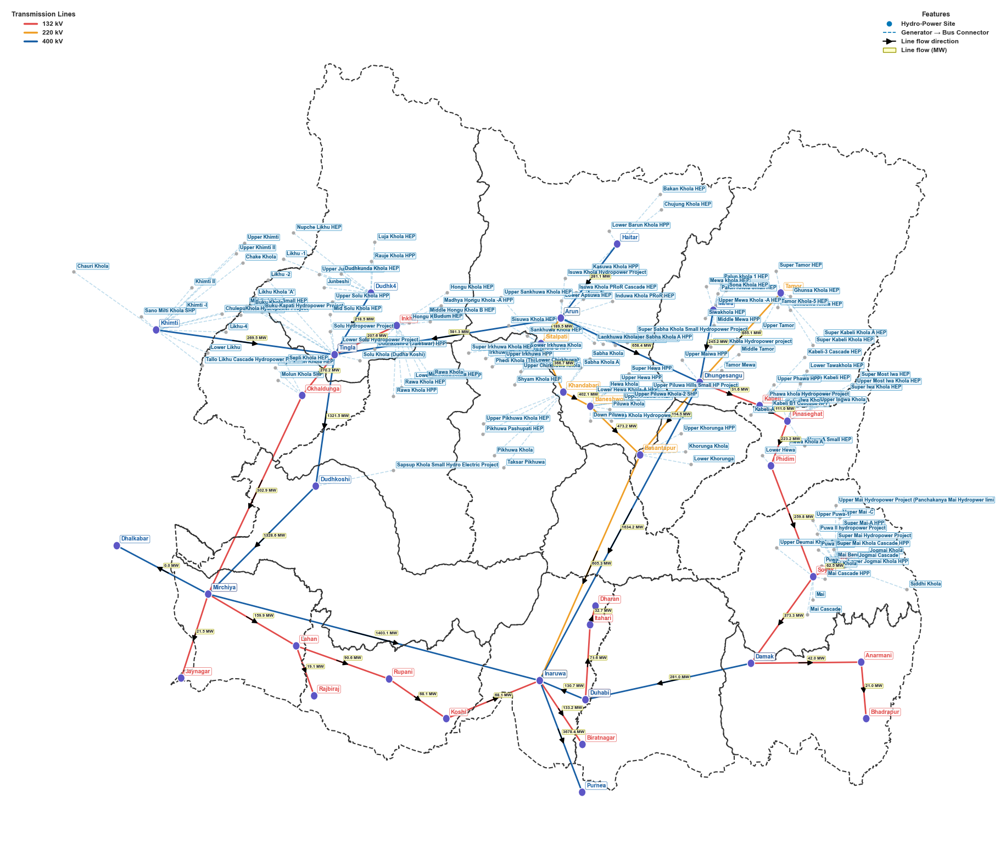

In [123]:

from Network_Plot import plot_network_flow
# ── Create figure & axes ONCE ──────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(40, 20))
fig.patch.set_facecolor('w')

# ── Pick snapshot by position (e.g. 5th timestep) ─────────────────────────────
fig, ax = plot_network_flow(base_n,snapshot=5207,ax=ax,show_gen_flow_arrows=False,show_flow_labels=True,show_flow_arrows=True)
plt.savefig('Images/case_study_map.pdf', dpi=300, bbox_inches='tight')


<Axes: xlabel='snapshot'>

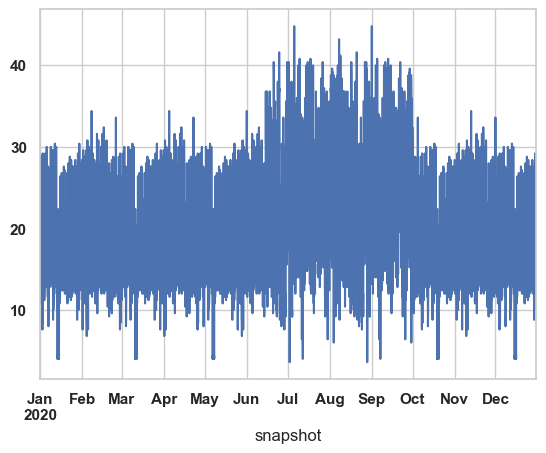

In [124]:
base_n.loads_t.p['RAJBIRAJ'].plot()

<Axes: xlabel='snapshot'>

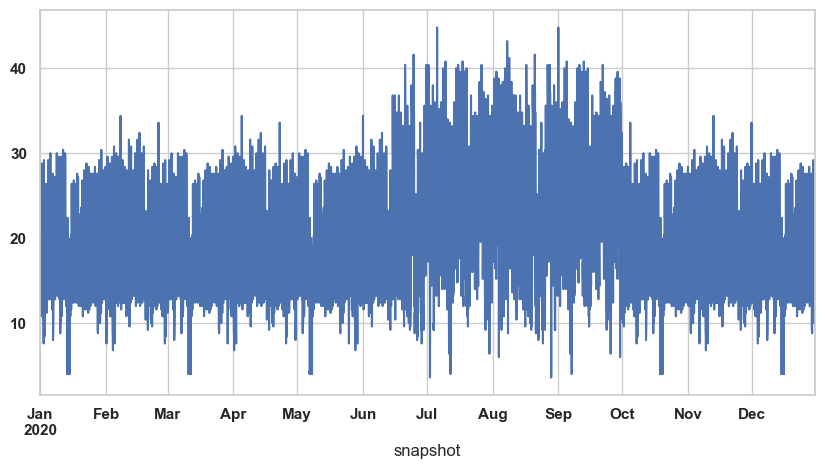

In [125]:
df = base_n.lines_t.p0['Lahan-Rajbiraj']
fig, ax = plt.subplots(figsize=(10, 5))
df.plot(ax=ax) 

#ax.set_xlim(pd.Timestamp(start_date), pd.Timestamp(end_date))

#### Security constrained

In [126]:
from Build_Network import Network_Base
from Scenario import Scenario_Analysis
load_growth_factor = 4

Base_n = Scenario_Analysis(Network_Base(IEX_mean,Cost_Scale),Hydro_Cost_per_MW,line_sub_cost,load_growth_factor,Cost_Scale=Cost_Scale)

DataFrame: 'buses' with 45 rows.
DataFrame: 'transformers' with 9 rows.
DataFrame: 'lines' with 41 rows.
DataFrame: 'line_types' with 21 rows.
DataFrame: 'loads' with 14 rows.
DataFrame: 'snapshots' with 8760 rows.
DataFrame: 'generators' with 144 rows.
DataFrame: 'carriers' with 4 rows.
DataFrame: 'loads_p_set' with 8760 rows.
DataFrame: 'p_max_pu' with 8760 rows.
                Snapshot  ANARMANI  BHADRAPUR  BIRATNAGAR  DAMAK  DHARAN  \
0    2020-01-01 00:00:00     12.62       4.00       26.20   7.30    5.76   
1    2020-01-01 01:00:00     11.10       4.20       23.95   7.00    5.00   
2    2020-01-01 02:00:00     10.47       4.25       23.50   9.25    4.90   
3    2020-01-01 03:00:00     10.37       4.50       23.45   6.75    5.22   
4    2020-01-01 04:00:00      9.73       4.50       23.80   7.13    5.29   
...                  ...       ...        ...         ...    ...     ...   
8755 2020-12-30 19:00:00     20.55       6.20       32.75  13.10    9.31   
8756 2020-12-30 20:00:00

In [127]:
# 2. Identify the top 3 most loaded transmission lines for contingencies
# (Using pre-computed power flows or running an initial standard LPF/OPF)
base_n.lpf(base_n.snapshots[5207]) # Run linear power flow to get initial flows
branch_outages = (base_n.lines_t.p0.loc[base_n.snapshots[5207]] / base_n.lines.s_nom).nlargest(2).index[1:]
print("Top 3 loaded lines selected for outages:", list(branch_outages))

INFO:pypsa.network.power_flow:Performing linear load-flow on AC sub-network <pypsa.networks.SubNetwork object at 0x30801ac10> for snapshot(s) DatetimeIndex(['2020-08-04 23:00:00'], dtype='datetime64[us]', name='snapshot', freq=None)


Top 3 loaded lines selected for outages: ['Tingla - Okhaldunga']


In [128]:
# 4. Run Security-Constrained Optimal Power Flow (SCLOPF)
# This ensures no branches overload even if any of these top lines trip (N-1 security)
base_n.optimize.optimize_security_constrained(
    snapshots=base_n.snapshots[5207],
    branch_outages=branch_outages,
    solver_name="highs"  # Replace with your solver (e.g., 'highs', 'gurobi', 'glpk')
)

/opt/miniconda3/envs/Power_Market_Updated/lib/python3.14/site-packages/pypsa/optimization/abstract.py:436: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  m = n.optimize.create_model(
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.05s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 248 primals, 789 duals
Objective: 2.13e+03
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Generator-p_set, Line-ext-s-lower, Line-ext-s-upper, Transformer-ext-s-lower, Transformer-ext-s-upper, Kirchhoff-Voltage-Law, Line-ext-s-lower-security-for-Line-outage-in-sub-networ

Running HiGHS 1.14.0 (git hash: n/a): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-fic1cw07 has 789 rows; 248 cols; 1294 nonzeros
Coefficient ranges:
  Matrix  [7e-03, 1e+02]
  Cost    [1e-02, 1e+00]
  Bound   [1e+04, 1e+04]
  RHS     [2e+00, 3e+04]
Presolving model
145 rows, 50 cols, 368 nonzeros 0s
125 rows, 40 cols, 391 nonzeros 0s
Dependent equations search running on 6 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
125 rows, 40 cols, 391 nonzeros 0s
Presolve reductions: rows 125(-664); columns 40(-208); nonzeros 391(-903) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0    -9.6774754294e-10 Ph1: 110(139132); Du: 0(7.41537e-12) 0.0s
         22     2.1286004036e+03 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-fic1cw07
Model status     

('ok', 'optimal')

In [129]:
# 5. Verify the post-contingency line loadings
p0_test = base_n.lpf_contingency(base_n.snapshots[5207], branch_outages=branch_outages)

INFO:pypsa.network.power_flow:Performing linear load-flow on AC sub-network <pypsa.networks.SubNetwork object at 0x30801ac10> for snapshot(s) DatetimeIndex(['2020-08-04 23:00:00'], dtype='datetime64[us]', name='snapshot', freq=None)


In [130]:
p0_test

base  (Line, Tingla - Okhaldunga)
component   name                                                             
Transformer Arun_ss                -9.586562e+02                -9.424795e+02
            Dhungesangu_ss2        -7.305881e+02                -7.222591e+02
            Inaruwa_ss2            -5.103462e+02                -4.975754e+02
            Damak_ss               -2.810369e+02                -2.827965e+02
            Mirchiya_ss            -7.444541e+01                 1.602419e+02
            Tingla_ss              -2.521587e+02                -5.223628e+02
            Dhungesangu_ss1        -1.900153e+02                -1.882556e+02
            Inaruwa_ss1             9.496275e+01                 1.304795e+02
            Duhabi_ss               1.503289e+02                 1.503289e+02
Line        Tingla- Inkhu          -2.075791e+02                -2.075791e+02
            Tingla - Okhaldunga     2.702041e+02                 0.000000e+00
            Okhaldunga-Mirchiya     3.028703e+02                 3.266623e+01
            Mirchiya-Lahan          1.599290e+02                 1.244122e+02
            Rupani-Koshi            6.811559e+01                 3.259887e+01
            Koshi-Inaruwa           6.811559e+01                 3.259887e+01
            Inaruwa-Biratnagar      1.331891e+02                 1.331891e+02
            Duhabi-Itahari          7.157661e+01                 7.157661e+01
            Itahari-Dharan          3.269661e+01                 3.269661e+01
            Dhungesangu-Kabeli      3.156079e+01                 3.332043e+01
            Kabeli-Pinaseghat_LILO  1.110189e+02                 1.127786e+02
            Pinaseghat_LILO-Phidim  2.231680e+02                 2.249277e+02
            phidim-Soyak_tap        2.597938e+02                 2.615535e+02
            Illam-Soyak_tap        -6.250250e+01                -6.250250e+01
            Illam-Damak            -3.732754e+02                -3.750351e+02
            Damak-Anarmani         -4.200000e+01                -4.200000e+01
            Anarmani-Bhadrapur      2.100000e+01                 2.100000e+01
            Lahan-Rajbiraj          1.909295e+01                 1.909295e+01
            Lahan-Rupani            9.059930e+01                 5.508258e+01
            Mirchiya-Jaynagar       2.146361e+01                 2.146361e+01
            Dhungesangu-Basantapur  1.145337e+02                 1.211029e+02
            Baneshwor-basantapur    4.731553e+02                 4.893319e+02
            Khandabari-Baneshwor    4.020568e+02                 4.182334e+02
            Sitalpati-Khandabari    3.667178e+02                 3.828945e+02
            Arun-Sitalpati          1.894837e+02                 2.056604e+02
            Dhungesangu-Tamor      -6.551065e+02                -6.551065e+02
            Inaruwa-Basantapur      6.053089e+02                 6.280549e+02
            Mirchiya-Dhalkabar4     5.896456e-13                 5.076137e-13
            Inaruwa-Duhabi          1.307080e+02                 1.324676e+02
            Duhabi-Damak           -2.810369e+02                -2.827965e+02
            Dudhkoshi-Tingla        1.321539e+03                 1.496776e+03
            Tingla- Arun           -5.813415e+02                -4.863747e+02
            Mirchiya-Dudhkoshi      1.328617e+03                 1.503855e+03
            Arun-U_Arun             2.811276e+02                 2.811276e+02
            Dhungesangu-Mewa       -2.452145e+02                -2.452145e+02
            Dhungesangu-Arun        6.584423e+02                 7.372324e+02
            Dhungesangu-Inaruwa     1.634245e+03                 1.704706e+03
            Dudhkoshi_4-Tingla     -2.185420e+02                -2.185420e+02
            Tingla-Khimti4         -2.694964e+02                -2.694964e+02
            Inaruwa-Purnea          3.678362e+03                 3.678362e+03
            Mirchiya-Inruwa4        1.403063e+03                 1

In [131]:

max_loading = (abs(p0_test.divide(base_n.passive_branches().s_nom, axis=0)).describe().loc["max"])

print("\nMaximum line loadings per contingency (should be <= 1.0):")
print(max_loading)


Maximum line loadings per contingency (should be <= 1.0):
base                           3.043353
(Line, Tingla - Okhaldunga)    3.264767
Name: max, dtype: float64


In [132]:
branch_outages

Index(['Tingla - Okhaldunga'], dtype='str', name='name')

INFO:pypsa.network.power_flow:Performing linear load-flow on AC sub-network <pypsa.networks.SubNetwork object at 0x17849e190> for snapshot(s) DatetimeIndex(['2020-08-04 23:00:00'], dtype='datetime64[us]', name='snapshot', freq=None)


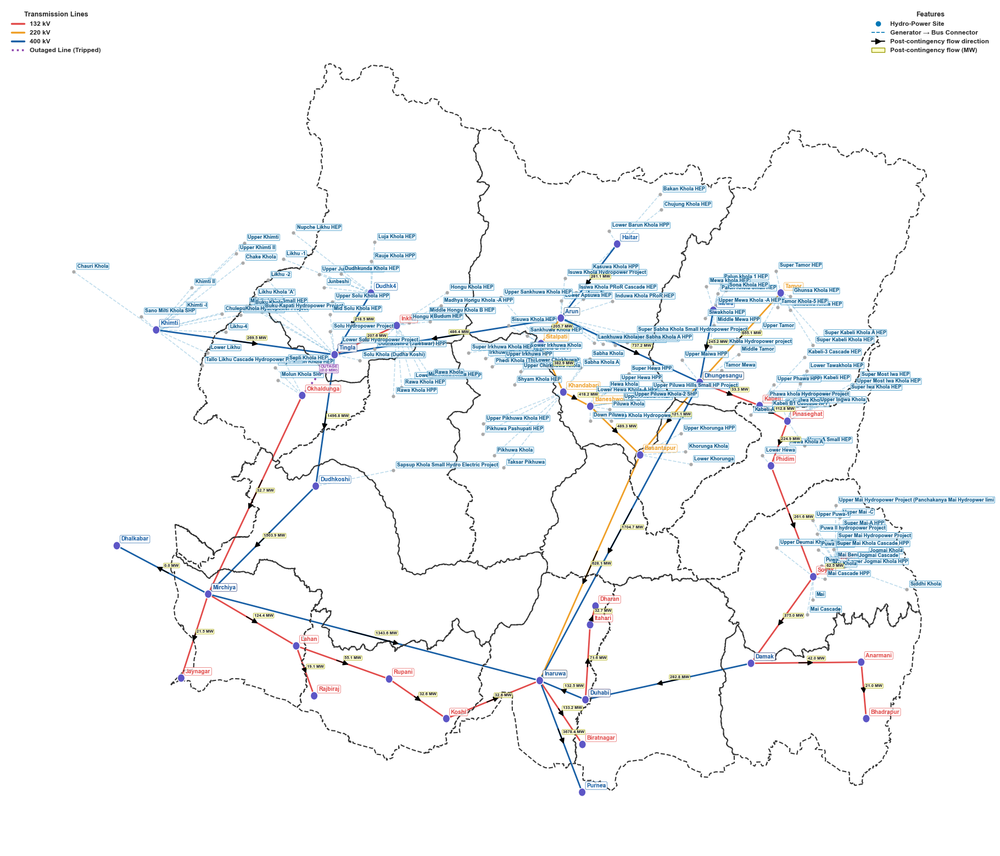

In [133]:

from Network_Plot import plot_network_flow
# ── Create figure & axes ONCE ──────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(40, 20))
fig.patch.set_facecolor('w')

# ── Pick snapshot by position (e.g. 5th timestep) ─────────────────────────────
fig, ax = plot_network_flow(base_n,snapshot=5207,branch_outages = branch_outages,ax=ax,show_gen_flow_arrows=False,show_flow_labels=True,show_flow_arrows=True)



<Axes: xlabel='snapshot'>

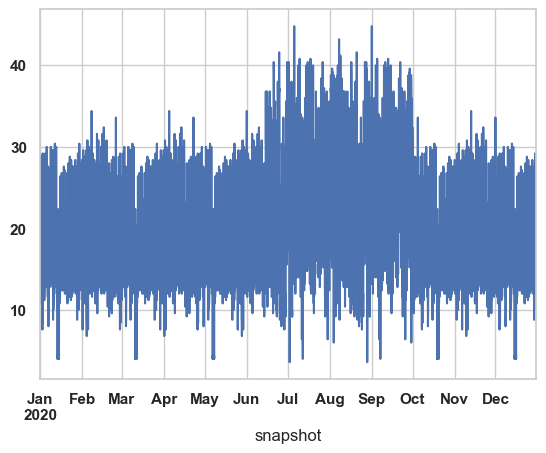

In [134]:
base_n.lines_t.p0['Lahan-Rajbiraj'].plot()

In [135]:
base_n.statistics()

Optimal Capacity  Installed Capacity  \
Generator   Dhalkebar Interconnection        1000.00000          1000.00000   
            Hydro                            4318.01200          4318.01200   
            Khimti Interconnection           2000.00000          2000.00000   
            Purnea Grid                      5000.00000          5000.00000   
Line        AC                              58218.19442         57702.23342   
Load        Internal Load                       0.00000             0.00000   
            Purnea Export                       0.00000             0.00000   
Transformer -                                3675.57330          1805.00000   

                                             Supply    Withdrawal  \
Generator   Dhalkebar Interconnection  0.000000e+00  0.000000e+00   
            Hydro                      2.801408e+07  0.000000e+00   
            Khimti Interconnection     0.000000e+00  0.000000e+00   
            Purnea Grid                2.173571e+07  0.000000e+00   
Line        AC                         1.966778e+07  9.371591e+07   
Load        Internal Load              0.000000e+00  5.949798e+06   
            Purnea Export              0.000000e+00  4.380000e+07   
Transformer -                          1.826358e+07  2.609077e+06   

                                       Energy Balance  Transmission  \
Generator   Dhalkebar Interconnection    0.000000e+00  0.000000e+00   
            Hydro                        2.801408e+07  0.000000e+00   
            Khimti Interconnection       0.000000e+00  0.000000e+00   
            Purnea Grid                  2.173571e+07  0.000000e+00   
Line        AC                          -7.404813e+07  7.404813e+07   
Load        Internal Load               -5.949798e+06  0.000000e+00   
            Purnea Export               -4.380000e+07  0.000000e+00   
Transformer -                            1.565451e+07 -1.565451e+07   

                                       Capacity Factor   Curtailment  \
Generator   Dhalkebar Interconnection         0.000000  8.760000e+06   
            Hydro                             0.740608  9.811701e+06   
            Khimti Interconnection            0.000000  1.752000e+07   
            Purnea Grid                       0.496249  2.206429e+07   
Line        AC                                0.222325  0.000000e+00   
Load        Internal Load                          NaN  0.000000e+00   
            Purnea Export                          NaN  0.000000e+00   
Transformer -                                 0.648259  0.000000e+00   

                                       Capital Expenditure  \
Generator   Dhalkebar Interconnection              0.00000   
            Hydro                              80449.95820   
            Khimti Interconnection                 0.00000   
            Purnea Grid                            0.00000   
Line        AC                                 13431.82695   
Load        Internal Load                          0.00000   
            Purnea Export                          0.00000   
Transformer -                                   3206.66475   

                                       Operational Expenditure       Revenue  \
Generator   Dhalkebar Interconnection                  0.00000       0.00000   
            Hydro                                      0.00000  192744.08083   
            Khimti Interconnection                     0.00000       0.00000   
            Purnea Grid                           162207.71502  162207.71502   
Line        AC                                         0.00000 -526306.31746   
Load        Internal Load                              0.00000  -44977.09881   
            Purnea Export                              0.00000 -319818.54758   
Transformer -                                          0.00000  110384.78288   

                                       Market Value  
Generator   Dhalkebar Interconnection           NaN  
            Hydro           

In [136]:
base_n.lines.s_nom_opt

name
Tingla- Inkhu              207.579061
Tingla - Okhaldunga        270.204058
Okhaldunga-Mirchiya        302.870291
Mirchiya-Lahan             196.622408
Rupani-Koshi               196.622408
Koshi-Inaruwa              196.622408
Inaruwa-Biratnagar         196.622408
Duhabi-Itahari             196.622408
Itahari-Dharan             196.622408
Dhungesangu-Kabeli         196.622408
Kabeli-Pinaseghat_LILO     196.622408
Pinaseghat_LILO-Phidim     224.927679
phidim-Soyak_tap           261.553455
Illam-Soyak_tap            196.622408
Illam-Damak                375.035079
Damak-Anarmani             196.622408
Anarmani-Bhadrapur         196.622408
Lahan-Rajbiraj             196.622408
Lahan-Rupani               196.622408
Mirchiya-Jaynagar          196.622408
Dhungesangu-Basantapur    1158.395580
Baneshwor-basantapur       996.829881
Khandabari-Baneshwor       996.829881
Sitalpati-Khandabari      1158.395580
Arun-Sitalpati            1158.395580
Dhungesangu-Tamor          996.829881
Inaruwa

#### Determiantion of Wheeling Charge

In [137]:
# ─────────────────────────────────────────────
# 5. METHOD 1 — MW-MILE WHEELING CHARGE
# ─────────────────────────────────────────────
# Principle: each MWh pays proportional to how much
# it uses each line (MW × km), normalized by total
# MW-mile usage across all transactions.
#
# Wheeling charge (NPR/MWh) for line l:
#   WC_l = Annual_Cost_l / Total_MWh_through_l
#
# System-wide wheeling rate:
#   WC_system = Σ(Annual_Cost_l) / Σ(|Flow_l| × Length_l × hours)
lines = Base_n.lines.copy()
print("\n── METHOD 1: MW-Mile Wheeling Charge ──")

mwmile = pd.DataFrame(index=lines.index)
mwmile["length_km"]        = lines["length"]
mwmile["s_nom_MVA"]        = lines["s_nom"]
mwmile["annual_cost_NPR"]  = lines["capital_cost"]

flows = base_n.lines_t.p0
# Total MWh through each line over the year
mwmile["total_MWh"] = flows.abs().sum()   # sum over 8760 hours (hourly = MWh)



# MW-Mile metric: |MW| × km summed over all hours
mwmile["mwmile_total"] = flows.abs().multiply(
    lines["length"], axis=1
).sum()

# Wheeling charge per MWh for each line (NPR/MWh)
mwmile["WC_per_MWh"] = (
    mwmile["annual_cost_NPR"] / mwmile["total_MWh"].replace(0, np.nan)
)

# System-wide average wheeling rate
total_annual_cost  = lines["capital_cost"].sum()
total_mwmile       = mwmile["mwmile_total"].sum()
total_MWh_system   = mwmile["total_MWh"].sum()

system_WC_mwmile   = total_annual_cost / total_mwmile          # NPR/MW-km
system_WC_per_MWh  = total_annual_cost / total_MWh_system      # NPR/MWh

print(f"System MW-Mile wheeling rate : NPR {system_WC_mwmile:.2f} / MW-km")
print(f"System average wheeling rate : NPR {system_WC_per_MWh*Cost_Scale} / MWh")
print(f"\nTop 10 most expensive lines (NPR/MWh):")
print(mwmile["WC_per_MWh"].sort_values(ascending=False).head(10).round(2))



── METHOD 1: MW-Mile Wheeling Charge ──
System MW-Mile wheeling rate : NPR 0.00 / MW-km
System average wheeling rate : NPR 0.14253461274966206 / MWh

Top 10 most expensive lines (NPR/MWh):
name
Mirchiya-Dhalkabar4       2.403992e+11
Mirchiya-Jaynagar         0.000000e+00
Lahan-Rajbiraj            0.000000e+00
Anarmani-Bhadrapur        0.000000e+00
Dhungesangu-Kabeli        0.000000e+00
Itahari-Dharan            0.000000e+00
Rupani-Koshi              0.000000e+00
Lahan-Rupani              0.000000e+00
Dhungesangu-Basantapur    0.000000e+00
Damak-Anarmani            0.000000e+00
Name: WC_per_MWh, dtype: float64


In [138]:
# ─────────────────────────────────────────────
# 6. METHOD 2 — POSTAGE STAMP WHEELING CHARGE
# ─────────────────────────────────────────────
# Uniform rate regardless of distance:
#   WC = Total Annual Network Cost / Total MWh wheeled

print("\n── METHOD 2: Postage Stamp Wheeling Charge ──")

total_MWh_load = Base_n.loads_t.p.sum().sum()   # total MWh consumed
postage_stamp_WC = total_annual_cost / total_MWh_load

print(f"Postage Stamp wheeling charge: NPR {postage_stamp_WC*Cost_Scale} / MWh")



── METHOD 2: Postage Stamp Wheeling Charge ──
Postage Stamp wheeling charge: NPR inf / MWh


/var/folders/zk/lh41nc414yl79qyknsg_d3kr0000gn/T/ipykernel_23925/3681593809.py:10: RuntimeWarning: divide by zero encountered in scalar divide
  postage_stamp_WC = total_annual_cost / total_MWh_load


In [139]:
# ─────────────────────────────────────────────
# 7. METHOD 3 — LMP-BASED CONGESTION COMPONENT
# ─────────────────────────────────────────────
# Wheeling charge = LMP_load_bus - LMP_gen_bus
# This is the nodal congestion component and
# reflects the true cost of using the network.

print("\n── METHOD 3: LMP-Based Wheeling Charge ──")

lmp = base_n.buses_t.marginal_price



# Identify generation buses (connected to generators)
gen_buses  = base_n.generators[
    base_n.generators.carrier.str.contains("hydro|hydro_ror|hydro_res",
                                       case=False, na=False)
].bus.unique()

# Identify load buses
load_buses = base_n.loads.bus.unique()

# Mean LMP at generation and load nodes
mean_lmp_gen  = lmp[[b for b in gen_buses  if b in lmp.columns]].mean(axis=1)
mean_lmp_load = lmp[[b for b in load_buses if b in lmp.columns]].mean(axis=1)

# LMP-based wheeling charge (time series)
lmp_wheeling = mean_lmp_load - mean_lmp_gen
lmp_wheeling = lmp_wheeling.clip(lower=0)   # negative = no congestion cost

print(f"Mean LMP-based wheeling charge : NPR {lmp_wheeling.mean()*Cost_Scale} / MWh")
print(f"Max  LMP-based wheeling charge : NPR {lmp_wheeling.max()*Cost_Scale} / MWh")
print(f"Hours with congestion charge>0 : {(lmp_wheeling > 0).sum()}")



── METHOD 3: LMP-Based Wheeling Charge ──
Mean LMP-based wheeling charge : NPR 283.0203779329778 / MWh
Max  LMP-based wheeling charge : NPR 1215325.5938422817 / MWh
Hours with congestion charge>0 : 3041


How a tranmission line developer would revover its cost if we use postage stamp method but the hydropower is still under construction and will be connected in future?

It is one of the most practical problem of tranmssion investment risk in Nepal's context. The core problem is; under the postage stamp wheeling:

$$WC = \frac{Total annual network cost}{Total MWh Wheeled}$$

If hydropower plants are still under construction, the denominator (MWh wheeled) is very small or zero during the construction period — meaning:

- The line is built and costs money today
- But the generation it was built to serve does not exist yet
- The wheeling charge either becomes astronomically high or the developer recovers nothing

This is called the Chicken-and-Egg problem of transmission investment. There are mainly five mechanism for cost recovery

- Guranteed Tranmssion Service Agreement (TSA)/ Take or Pay

The most common solution globally. Before the line is built, the transmission developer signs a long-term contract with the future hydro project developer:
Annual Payment=Capacity Charge×Reserved MW\text{Annual Payment} = \text{Capacity Charge} \times \text{Reserved MW}Annual Payment=Capacity Charge×Reserved MW
The hydro developer pays a reservation fee for MW capacity on the line regardless of whether the plant is generating. This mirrors a take-or-pay gas contract.
In Nepal's context:

NEA or the hydro IPP signs a 25–30 year TSA with the transmission developer
Payment begins when the line is commissioned, not when generation starts
The hydro developer accepts this risk because without the line, they cannot sell power at all

- Rolled In cost recovery (Regulatory Compact)

The regulator (ERRA in Nepal) allows the transmission developer to roll the new line's cost into the existing postage stamp rate charged to all existing users, even before the new generator connects.
WCnew=Existing Network Cost+New Line CostExisting MWh WheeledWC_{new} = \frac{\text{Existing Network Cost} + \text{New Line Cost}}{\text{Existing MWh Wheeled}}WCnew​=Existing MWh WheeledExisting Network Cost+New Line Cost​
Effectively, existing users cross-subsidize the new infrastructure during the construction gap.
Pros: Transmission developer has guaranteed revenue from day one
Cons: Existing users pay more for infrastructure that doesn't benefit them yet — politically difficult
Real example: This is how most U.S. regulated utilities recover transmission costs under FERC Order 1000, and how India's CTU (Central Transmission Utility) recovers costs under the PGCIL model.

- Avaibility Based Tariff (ABT)/Capacity Payment

Instead of recovering cost only when energy flows, the developer recovers cost based on line avaibility-whether the line is ready to tranmit, regardless of actual use.

$$Annual Revenue = Capacity Tariff (NPR/MW/year) \times Installed Capacity (MW)$$

Fixed capacity charge MW of capacity reserved Recover capital cost (debt service)

Variable energy chargeMWh actually transmitted Recover O&M cost

The fixed charge is paid regardless of flows — solving the underutilization problem during construction. This is exactly how India's inter-state transmission system (ISTS) works under the CERC model, and is the most relevant precedent for Nepal given the India interconnection.

- Government Viability Gap Funding (VGF)

Where private transmission investment is commercially unviable during the construction gap, the government provides a viability gap payment to bridge the revenue shortfall:
VGF=Annual Debt Service−Actual Wheeling Revenue CollectedVGF = \text{Annual Debt Service} - \text{Actual Wheeling Revenue Collected}VGF=Annual Debt Service−Actual Wheeling Revenue Collected
This is common in South Asian infrastructure where generation and transmission timelines are misaligned. The World Bank and ADB have funded VGF mechanisms in Bangladesh, Pakistan, and India for exactly this scenario.
In Nepal, the government could provide VGF to NEA or a private transmission developer for lines built ahead of hydropower commissioning, treating it as a public good investment in anticipation of future export revenue.

Line CAPEX          : NPR 3.40 Billion
Annual Annuity      : NPR 411.7 Million/year

── Cost Recovery Timeline: Inaruwa-Purnea ──

 Year  CF_ramp  MWh_wheeled (GWh)  WC_uncapped (NPR/MWh)  WC_capped (NPR/MWh)  Revenue_capped (M NPR)  Gap (M NPR)  Cumulative_gap (M NPR)
    1     0.10              337.3                 1220.6                500.0                   168.6        243.0                   243.0
    2     0.25              843.2                  488.3                488.3                   411.7          0.0                   243.0
    3     0.45             1517.7                  271.3                271.3                   411.7          0.0                   243.0
    4     0.65             2192.2                  187.8                187.8                   411.7         -0.0                   243.0
    5     0.80             2698.1                  152.6                152.6                   411.7          0.0                   243.0
    6     0.90             3035.3  

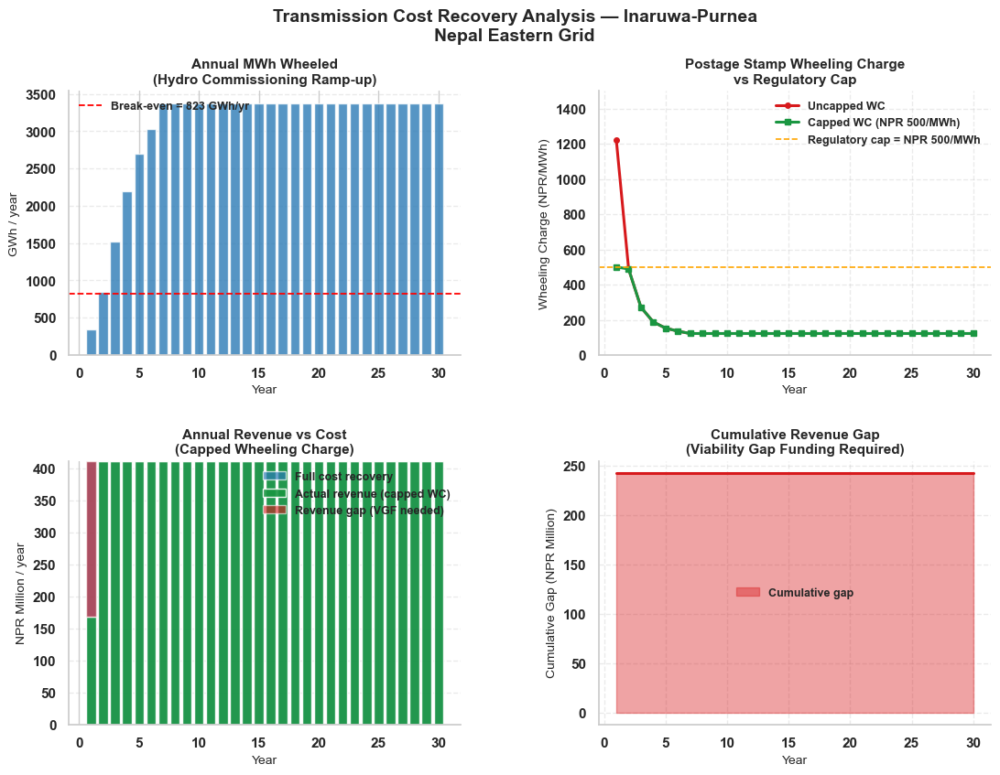

Saved → wheeling_cost_recovery.png
Saved → wheeling_cost_recovery_timeline.csv


In [140]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ─────────────────────────────────────────────
# CONFIGURATION
# ─────────────────────────────────────────────

LINE_NAME       = "Inaruwa-Purnea"
S_NOM_MVA       = 700          # thermal capacity
LENGTH_KM       = 85           # line length
V_KV            = 400
COST_PER_KM     = 40e6         # NPR/km for 400kV
ANNUITY_RATE    = 0.10
LIFETIME_YRS    = 30
CAPACITY_FACTOR_RAMP = {       # hydro capacity factor ramping up over years
    1:  0.10,   # Year 1: 10% of plants commissioned
    2:  0.25,
    3:  0.45,
    4:  0.65,
    5:  0.80,
    6:  0.90,
    7:  1.00,   # Year 7: fully commissioned
}
HOURS_PER_YEAR  = 8760
LOAD_FACTOR     = 0.55         # average line load factor when operating

# ─────────────────────────────────────────────
# 1. LINE ANNUAL COST
# ─────────────────────────────────────────────

capex       = COST_PER_KM * LENGTH_KM
r, n_yr     = ANNUITY_RATE, LIFETIME_YRS
annuity     = capex * (r * (1+r)**n_yr) / ((1+r)**n_yr - 1)
oandm       = 0.015 * capex    # 1.5% of CAPEX per year
annual_cost = annuity + oandm

print(f"Line CAPEX          : NPR {capex/1e9:.2f} Billion")
print(f"Annual Annuity      : NPR {annual_cost/1e6:.1f} Million/year")

# ─────────────────────────────────────────────
# 2. POSTAGE STAMP RECOVERY OVER COMMISSIONING PERIOD
# ─────────────────────────────────────────────

years       = list(range(1, LIFETIME_YRS + 1))
results     = []

for yr in years:
    # Capacity factor ramps up in early years, then stays at 1.0
    cf = CAPACITY_FACTOR_RAMP.get(yr, 1.0)

    # MWh wheeled this year
    mwh_wheeled = S_NOM_MVA * LOAD_FACTOR * cf * HOURS_PER_YEAR

    # Postage stamp WC this year
    wc_per_mwh  = annual_cost / mwh_wheeled if mwh_wheeled > 0 else np.inf

    # Revenue collected
    revenue     = wc_per_mwh * mwh_wheeled  # = annual_cost if fully utilized

    # Revenue gap (shortfall from full cost recovery)
    gap         = annual_cost - revenue      # always 0 under pure postage stamp
                                             # gap appears when WC is CAPPED

    # If regulator caps WC at a reasonable level (e.g. NPR 500/MWh max)
    WC_CAP      = 500   # NPR/MWh — regulatory ceiling
    wc_capped   = min(wc_per_mwh, WC_CAP)
    revenue_capped = wc_capped * mwh_wheeled
    gap_capped  = annual_cost - revenue_capped

    results.append({
        "Year":              yr,
        "CF_ramp":           round(cf, 2),
        "MWh_wheeled (GWh)": round(mwh_wheeled / 1e3, 1),
        "WC_uncapped (NPR/MWh)": round(wc_per_mwh, 1) if wc_per_mwh < 1e6 else 9999,
        "WC_capped (NPR/MWh)":   round(wc_capped, 1),
        "Revenue_full (M NPR)":  round(annual_cost / 1e6, 1),
        "Revenue_capped (M NPR)": round(revenue_capped / 1e6, 1),
        "Gap (M NPR)":           round(gap_capped / 1e6, 1),
        "Cumulative_gap (M NPR)": 0,   # filled below
    })

df = pd.DataFrame(results)
df["Cumulative_gap (M NPR)"] = df["Gap (M NPR)"].cumsum()

print(f"\n── Cost Recovery Timeline: {LINE_NAME} ──\n")
print(df[["Year", "CF_ramp", "MWh_wheeled (GWh)",
          "WC_uncapped (NPR/MWh)", "WC_capped (NPR/MWh)",
          "Revenue_capped (M NPR)", "Gap (M NPR)",
          "Cumulative_gap (M NPR)"]].to_string(index=False))

# ─────────────────────────────────────────────
# 3. BREAK-EVEN ANALYSIS
# ─────────────────────────────────────────────

# At what MWh utilization does WC = WC_CAP?
breakeven_mwh = annual_cost / WC_CAP
breakeven_cf  = breakeven_mwh / (S_NOM_MVA * LOAD_FACTOR * HOURS_PER_YEAR)
print(f"\nBreak-even utilization for WC = NPR {WC_CAP}/MWh:")
print(f"  Required MWh/year : {breakeven_mwh/1e3:.1f} GWh")
print(f"  Required CF ramp  : {breakeven_cf:.2f} ({breakeven_cf*100:.0f}%)")

# ─────────────────────────────────────────────
# 4. PLOT
# ─────────────────────────────────────────────

fig, axes = plt.subplots(2, 2, figsize=(13, 9),
                          gridspec_kw={"hspace": 0.4, "wspace": 0.35})

# ── Plot 1: MWh wheeled ramp-up ──
ax = axes[0, 0]
ax.bar(df["Year"], df["MWh_wheeled (GWh)"],
       color="#2C7BB6", alpha=0.8, edgecolor="white")
ax.axhline(breakeven_mwh / 1e3, color="red", linestyle="--",
           linewidth=1.3, label=f"Break-even = {breakeven_mwh/1e3:.0f} GWh/yr")
ax.set_title("Annual MWh Wheeled\n(Hydro Commissioning Ramp-up)", fontsize=11, fontweight="bold")
ax.set_ylabel("GWh / year", fontsize=10)
ax.set_xlabel("Year", fontsize=10)
ax.legend(fontsize=9)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

# ── Plot 2: Wheeling charge over time ──
ax = axes[0, 1]
ax.plot(df["Year"], df["WC_uncapped (NPR/MWh)"].replace(9999, np.nan),
        color="#D7191C", linewidth=2.2, label="Uncapped WC", marker="o", ms=4)
ax.plot(df["Year"], df["WC_capped (NPR/MWh)"],
        color="#1A9641", linewidth=2.2, label=f"Capped WC (NPR {WC_CAP}/MWh)", marker="s", ms=4)
ax.axhline(WC_CAP, color="orange", linestyle="--",
           linewidth=1.2, label=f"Regulatory cap = NPR {WC_CAP}/MWh")
ax.set_title("Postage Stamp Wheeling Charge\nvs Regulatory Cap", fontsize=11, fontweight="bold")
ax.set_ylabel("Wheeling Charge (NPR/MWh)", fontsize=10)
ax.set_xlabel("Year", fontsize=10)
ax.set_ylim(0, WC_CAP * 3)
ax.legend(fontsize=9)
ax.grid(linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

# ── Plot 3: Revenue vs cost ──
ax = axes[1, 0]
ax.bar(df["Year"], df["Revenue_full (M NPR)"],
       color="#2C7BB6", alpha=0.7, label="Full cost recovery", edgecolor="white")
ax.bar(df["Year"], df["Revenue_capped (M NPR)"],
       color="#1A9641", alpha=0.9, label="Actual revenue (capped WC)", edgecolor="white")
ax.bar(df["Year"], df["Gap (M NPR)"],
       bottom=df["Revenue_capped (M NPR)"],
       color="#D7191C", alpha=0.6, label="Revenue gap (VGF needed)", edgecolor="white")
ax.set_title("Annual Revenue vs Cost\n(Capped Wheeling Charge)", fontsize=11, fontweight="bold")
ax.set_ylabel("NPR Million / year", fontsize=10)
ax.set_xlabel("Year", fontsize=10)
ax.legend(fontsize=9)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

# ── Plot 4: Cumulative revenue gap (VGF requirement) ──
ax = axes[1, 1]
ax.fill_between(df["Year"], df["Cumulative_gap (M NPR)"],
                alpha=0.4, color="#D7191C", label="Cumulative gap")
ax.plot(df["Year"], df["Cumulative_gap (M NPR)"],
        color="#D7191C", linewidth=2.2)
ax.set_title("Cumulative Revenue Gap\n(Viability Gap Funding Required)", fontsize=11, fontweight="bold")
ax.set_ylabel("Cumulative Gap (NPR Million)", fontsize=10)
ax.set_xlabel("Year", fontsize=10)
ax.grid(linestyle="--", alpha=0.4)
ax.legend(fontsize=9)
ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(f"Transmission Cost Recovery Analysis — {LINE_NAME}\nNepal Eastern Grid",
             fontsize=14, fontweight="bold")
plt.savefig("wheeling_cost_recovery.png", dpi=180, bbox_inches="tight")
plt.show()

df.to_csv("wheeling_cost_recovery_timeline.csv", index=False)
print("Saved → wheeling_cost_recovery.png")
print("Saved → wheeling_cost_recovery_timeline.csv")

In [141]:
system_WC_per_MWh*Cost_Scale

np.float64(0.14253461274966206)

### Scenario Analysis

In [142]:
from Build_Network import Network_Base
from Scenario import Scenario_Analysis

load_growth_factor = 4
Base_n = Scenario_Analysis(Network_Base(IEX_mean,Cost_Scale),Hydro_Cost_per_MW,line_sub_cost,load_growth_factor,Cost_Scale=Cost_Scale)

DataFrame: 'buses' with 45 rows.
DataFrame: 'transformers' with 9 rows.
DataFrame: 'lines' with 41 rows.
DataFrame: 'line_types' with 21 rows.
DataFrame: 'loads' with 14 rows.
DataFrame: 'snapshots' with 8760 rows.
DataFrame: 'generators' with 144 rows.
DataFrame: 'carriers' with 4 rows.
DataFrame: 'loads_p_set' with 8760 rows.
DataFrame: 'p_max_pu' with 8760 rows.
                Snapshot  ANARMANI  BHADRAPUR  BIRATNAGAR  DAMAK  DHARAN  \
0    2020-01-01 00:00:00     12.62       4.00       26.20   7.30    5.76   
1    2020-01-01 01:00:00     11.10       4.20       23.95   7.00    5.00   
2    2020-01-01 02:00:00     10.47       4.25       23.50   9.25    4.90   
3    2020-01-01 03:00:00     10.37       4.50       23.45   6.75    5.22   
4    2020-01-01 04:00:00      9.73       4.50       23.80   7.13    5.29   
...                  ...       ...        ...         ...    ...     ...   
8755 2020-12-30 19:00:00     20.55       6.20       32.75  13.10    9.31   
8756 2020-12-30 20:00:00

In [143]:
def get_max_snapshot(senario):
    flow_abs = senario.lines_t.p0.abs()
    # ── For a specific line ───────────────────────────────────────────────────────
    line_name = "Inaruwa-Purnea"
    max_snapshot = flow_abs[line_name].idxmax()
    max_value = flow_abs[line_name].max()
    print(f"Line '{line_name}' peaks at {max_value:.2f} MW on snapshot {max_snapshot}")

    # ── For ALL lines at once (snapshot + value of their individual peak) ────────
    peak_snapshot = flow_abs.idxmax()   # snapshot of max flow, per line
    peak_value = flow_abs.max()         # max flow value, per line

    peak_summary = pd.DataFrame({
        "peak_flow_MW": peak_value,
        "snapshot": peak_snapshot
    }).sort_values("peak_flow_MW", ascending=False)

    max_snapshot_number = flow_abs[line_name].values.argmax()
    max_value = flow_abs[line_name].values[max_snapshot_number]
    print(f"Line '{line_name}' peaks at {max_value:.2f} MW at snapshot #{max_snapshot_number}")
    return int(max_snapshot_number)

In [144]:
### _t contiant what i have given input

In [145]:
scenarios = ['Base',"Low Discharge","High Discharge", "High Load Growth", "Low Load Growth", "Low IEX","High IEX","Security Constraint"]
Base_n.set_scenarios({scenarios[0]:0.2, scenarios[1]:0.2,scenarios[2]:0.1,scenarios[3]:0.1,scenarios[4]:0.1,scenarios[5]:0.1,scenarios[6]:0.1,scenarios[7]:0.1})

In [146]:
meanpuval = p_max_pu_mean.reshape(-1, 1)
base_p_set = Base_n.generators_t.p_set.loc[:,"Base"].values 
norm_p_set = base_p_set/ meanpuval
high_dis_p_set = norm_p_set*p_max_pu_upper.reshape(-1,1)
low_dis_p_set = norm_p_set*p_max_pu_lower.reshape(-1,1)

Base_n.generators_t.p_set.loc[:,"High Discharge"] = high_dis_p_set
Base_n.generators_t.p_set.loc[:,"Low Discharge"] = low_dis_p_set

Base_n.loads_t.p_set.loc[:,"High Load Growth"] = Base_n.loads_t.p_set.loc[:,"Base"].values*1.5
Base_n.loads_t.p_set.loc[:,"Low Load Growth"] = Base_n.loads_t.p_set.loc[:,"Base"].values*0.5
Base_n.generators_t.marginal_cost.loc[:,"Low IEX"] = IEX_lower/Cost_Scale
Base_n.generators_t.marginal_cost.loc[:,"High IEX"] = IEX_upper/Cost_Scale

In [147]:
solve_Scenarios = {}
for sen in scenarios:
    variable_name = f"{sen}"
    senario = Base_n.get_scenario(sen)
    senario.optimize()
    if sen == "Security Constraint":
        max_snapshot = solve_Scenarios['Base'].snapshots[get_max_snapshot(solve_Scenarios['Base'])]
        branch_outages = (senario.lines_t.p0.loc[max_snapshot] / senario.lines.s_nom).nlargest(3).index[1:] ## for top 3 most loaded tranmission line
        senario.optimize.optimize_security_constrained(branch_outages=branch_outages, log_to_console=False)
        solve_Scenarios[variable_name] = senario
        
    else:
        solve_Scenarios[variable_name] = senario
        

/var/folders/zk/lh41nc414yl79qyknsg_d3kr0000gn/T/ipykernel_23925/885765153.py:5: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  senario.optimize()
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 6/6 [00:00<00:00, 174.96it/s]
INFO:linopy.io: Writing time: 0.57s


Running HiGHS 1.14.0 (git hash: n/a): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-h6jaz1h8 has 5159740 rows; 1725771 cols; 8164420 nonzeros
Coefficient ranges:
  Matrix  [1e+00, 1e+02]
  Cost    [9e-04, 1e+00]
  Bound   [1e+04, 1e+04]
  RHS     [3e-02, 3e+04]
Presolving model
770880 rows, 157712 cols, 1734480 nonzeros 1s
639478 rows, 105150 cols, 1656688 nonzeros 2s
Dependent equations search running on 69296 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 1.17s (limit = 1000.00s)
621176 rows, 86848 cols, 1734506 nonzeros 4s
Presolve reductions: rows 621176(-4538564); columns 86848(-1638923); nonzeros 1734506(-6429914) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     7.1049168805e-07 Ph1: 489418(6.08936e+08); Du: 0(7.20009e-08) 4.4s
      75388     1.6458690690e+05 Pr: 0(0) 7.1s

Performed postsolve
Solving the original LP from the solution aft

INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 1725771 primals, 5159740 duals
Objective: 1.65e+05
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Generator-p_set, Line-ext-s-lower, Line-ext-s-upper, Transformer-ext-s-lower, Transformer-ext-s-upper, Kirchhoff-Voltage-Law were not assigned to the network.
/var/folders/zk/lh41nc414yl79qyknsg_d3kr0000gn/T/ipykernel_23925/885765153.py:5: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  senario.optimize()
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 6/6 

Running HiGHS 1.14.0 (git hash: n/a): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-8lb1dyml has 5159740 rows; 1725771 cols; 8164420 nonzeros
Coefficient ranges:
  Matrix  [1e+00, 1e+02]
  Cost    [9e-04, 1e+00]
  Bound   [1e+04, 1e+04]
  RHS     [3e-02, 3e+04]
Presolving model
770880 rows, 157712 cols, 1734480 nonzeros 1s
639478 rows, 105150 cols, 1656688 nonzeros 2s
Dependent equations search running on 69296 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 1.16s (limit = 1000.00s)
621176 rows, 86848 cols, 1734506 nonzeros 4s
Presolve reductions: rows 621176(-4538564); columns 86848(-1638923); nonzeros 1734506(-6429914) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     7.1049168805e-07 Ph1: 489418(6.08936e+08); Du: 0(7.20009e-08) 4.4s
      75311     1.7734480265e+05 Pr: 0(0) 7.0s

Performed postsolve
Solving the original LP from the solution aft

INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 1725771 primals, 5159740 duals
Objective: 1.77e+05
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Generator-p_set, Line-ext-s-lower, Line-ext-s-upper, Transformer-ext-s-lower, Transformer-ext-s-upper, Kirchhoff-Voltage-Law were not assigned to the network.
/var/folders/zk/lh41nc414yl79qyknsg_d3kr0000gn/T/ipykernel_23925/885765153.py:5: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  senario.optimize()
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 6/6 

...

INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 1725771 primals, 5159740 duals
Objective: 2.14e+05
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Generator-p_set, Line-ext-s-lower, Line-ext-s-upper, Transformer-ext-s-lower, Transformer-ext-s-upper, Kirchhoff-Voltage-Law were not assigned to the network.
/var/folders/zk/lh41nc414yl79qyknsg_d3kr0000gn/T/ipykernel_23925/885765153.py:5: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  senario.optimize()
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 6/6 

Running HiGHS 1.14.0 (git hash: n/a): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-t5edskup has 5159740 rows; 1725771 cols; 8164420 nonzeros
Coefficient ranges:
  Matrix  [1e+00, 1e+02]
  Cost    [9e-04, 1e+00]
  Bound   [1e+04, 1e+04]
  RHS     [3e-02, 3e+04]
Presolving model
770880 rows, 157712 cols, 1734480 nonzeros 1s
639478 rows, 105150 cols, 1656688 nonzeros 2s
Dependent equations search running on 69296 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 1.18s (limit = 1000.00s)
621176 rows, 86848 cols, 1734506 nonzeros 4s
Presolve reductions: rows 621176(-4538564); columns 86848(-1638923); nonzeros 1734506(-6429914) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     7.1049168805e-07 Ph1: 489418(6.08936e+08); Du: 0(7.20009e-08) 4.5s
      75388     1.6458690690e+05 Pr: 0(0) 7.1s

Performed postsolve
Solving the original LP from the solution aft

INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 1725771 primals, 5159740 duals
Objective: 1.65e+05
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Generator-p_set, Line-ext-s-lower, Line-ext-s-upper, Transformer-ext-s-lower, Transformer-ext-s-upper, Kirchhoff-Voltage-Law were not assigned to the network.
/opt/miniconda3/envs/Power_Market_Updated/lib/python3.14/site-packages/pypsa/optimization/abstract.py:436: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  m = n.optimize.create_model(


Line 'Inaruwa-Purnea' peaks at 3780.07 MW on snapshot 2020-09-07 08:00:00
Line 'Inaruwa-Purnea' peaks at 3780.07 MW at snapshot #6008


INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.model:Solver options:
 - log_to_console: False
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 6/6 [00:00<00:00, 160.62it/s]
INFO:linopy.io: Writing time: 1.19s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 1725771 primals, 6911740 duals
Objective: 1.65e+05
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Generator-p_set, Line-ext-s-lower, Line-ext-s-upper, Transformer-ext-s-lower, Transformer-ext-s-upper, Kirchhoff-Voltage-Law, Line-ext-s-lower-security-for-Line-outage-in-sub-network-0, Line-ext-s-upper-security-for-Line-outage-in-sub-network-0, Transformer-ext-s-lower-security-for-Line-outage-in-sub-network-0, Transformer-ext-s-upper-security-for-Line-outage-in-sub-network-0 were not assigned to the network.


In [148]:
import pandas as pd

# Define the components/carriers you care about
targets = {
    "Hydro": ("Generator", "Hydro"),
    "Purnea": ("Generator", "Purnea Grid"),
    "Internal Load": ("Load", "Internal Load"),
    "Purnea Load": ("Load", "Purnea Export"),
}

# Metrics you want
metrics = [
    "Supply",
    "Withdrawal",
    "Energy Balance",
    "Capacity Factor",
    "Revenue",
    "Capital Expenditure",
    "Market Value",
]

results = pd.DataFrame(index=scenarios)

for label, (component, carrier) in targets.items():
    for metric in metrics:
        col_name = f"{label} {metric}"
        values = []
        for sen in scenarios:
            stats = solve_Scenarios[sen].statistics()
            try:
                val = stats[metric].loc[(component, carrier)]
            except KeyError:
                val = np.nan  # in case that combination doesn't exist for a scenario
            values.append(val)
        results[col_name] = values

results

,Hydro Supply,Hydro Withdrawal,Hydro Energy Balance,Hydro Capacity Factor,Hydro Revenue,Hydro Capital Expenditure,Hydro Market Value,Purnea Supply,Purnea Withdrawal,Purnea Energy Balance,...,Internal Load Revenue,Internal Load Capital Expenditure,Internal Load Market Value,Purnea Load Supply,Purnea Load Withdrawal,Purnea Load Energy Balance,Purnea Load Capacity Factor,Purnea Load Revenue,Purnea Load Capital Expenditure,Purnea Load Market Value
Base,2.801408e+07,0.0,2.801408e+07,0.740608,197401.03568,80449.9582,0.007046,2.173571e+07,0.0,2.173571e+07,...,-44924.13743,0.0,-0.007551,0.0,43800000.0,-43800000.0,NaN,-319818.54758,0.0,-0.007302
Low Discharge,2.629223e+07,0.0,2.629223e+07,0.695087,184643.13993,80449.9582,0.007023,2.345757e+07,0.0,2.345757e+07,...,-44924.13743,0.0,-0.007551,0.0,43800000.0,-43800000.0,NaN,-319818.54758,0.0,-0.007302
High Discharge,2.973594e+07,0.0,2.973594e+07,0.786129,210154.87708,80449.9582,0.007067,2.001386e+07,0.0,2.001386e+07,...,-44925.41722,0.0,-0.007551,0.0,43800000.0,-43800000.0,NaN,-319818.54758,0.0,-0.007302
High Load Growth,2.801408e+07,0.0,2.801408e+07,0.740608,197868.38717,80449.9582,0.007063,2.471061e+07,0.0,2.471061e+07,...,-68130.80650,0.0,-0.007634,0.0,43800000.0,-43800000.0,NaN,-319818.54758,0.0,-0.007302
Low Load Growth,2.801408e+07,0.0,2.801408e+07,0.740608,197387.41267,80449.9582,0.007046,1.876082e+07,0.0,1.876082e+07,...,-22267.46329,0.0,-0.007485,0.0,43800000.0,-43800000.0,NaN,-319818.54758,0.0,-0.007302
Low IEX,2.801408e+07,0.0,2.801408e+07,0.740608,133036.38829,80449.9582,0.004749,2.173571e+07,0.0,2.173571e+07,...,-31062.23069,0.0,-0.005221,0.0,43800000.0,-43800000.0,NaN,-219840.43287,0.0,-0.005019
High IEX,2.801408e+07,0.0,2.801408e+07,0.740608,261765.68307,80449.9582,0.009344,2.173571e+07,0.0,2.173571e+07,...,-58786.04416,0.0,-0.009880,0.0,43800000.0,-43800000.0,NaN,-419796.66228,0.0,-0.009584
Security Constraint,2.801408e+07,0.0,2.801408e+07,0.740608,196697.81696,80449.9582,0.007021,2.173571e+07,0.0,2.173571e+07,...,-45298.10668,0.0,-0.007613,0.0,43800000.0,-43800000.0,NaN,-319818.54758,0.0,-0.007302


In [149]:
results.columns

Index(['Hydro Supply', 'Hydro Withdrawal', 'Hydro Energy Balance',
       'Hydro Capacity Factor', 'Hydro Revenue', 'Hydro Capital Expenditure',
       'Hydro Market Value', 'Purnea Supply', 'Purnea Withdrawal',
       'Purnea Energy Balance', 'Purnea Capacity Factor', 'Purnea Revenue',
       'Purnea Capital Expenditure', 'Purnea Market Value',
       'Internal Load Supply', 'Internal Load Withdrawal',
       'Internal Load Energy Balance', 'Internal Load Capacity Factor',
       'Internal Load Revenue', 'Internal Load Capital Expenditure',
       'Internal Load Market Value', 'Purnea Load Supply',
       'Purnea Load Withdrawal', 'Purnea Load Energy Balance',
       'Purnea Load Capacity Factor', 'Purnea Load Revenue',
       'Purnea Load Capital Expenditure', 'Purnea Load Market Value'],
      dtype='str')

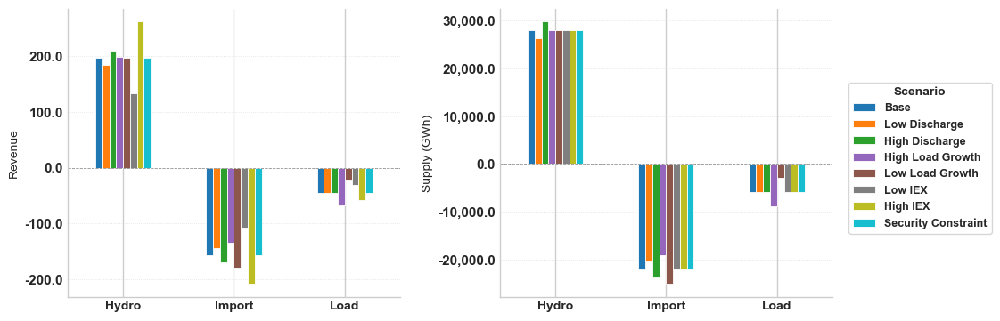

In [181]:

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ── Reshape results into per-metric DataFrames (index=component label, columns=scenario) ──

labels = ["Hydro", "Purnea", "Internal Load", "Purnea Load"]

def get_metric_df(results, metric, labels):
    """Build a DataFrame: index = component label, columns = scenario, values = metric."""
    data = {}
    for label in labels:
        col = f"{label} {metric}"
        if col in results.columns:
            data[label] = results[col]
    df = pd.DataFrame(data).T
    df.columns.name = "Scenario"
    return df

def build_panel(results, metric, scale=1.0):
    df = get_metric_df(results, metric, labels)

    if metric == "Supply":
        withdrawal_df = get_metric_df(results, "Withdrawal", labels)
        df.loc["Tie Line Import"] = df.loc["Purnea"] - withdrawal_df.loc["Purnea Load"]
        df.loc["Internal Load"] = -withdrawal_df.loc["Internal Load"]
    elif metric == "Withdrawal":
        df.loc["Tie Line Import"] = df.loc["Purnea Load"]
    elif metric == "Revenue":
        df.loc["Tie Line Import"] = df.loc["Purnea"] + df.loc["Purnea Load"]
    elif metric == "Market Value":
        df.loc["Tie Line Import"] = df.loc["Purnea"]

    df = df.loc[["Hydro", "Tie Line Import", "Internal Load"]]
    return df * scale

revenue_df     = build_panel(results, "Revenue",      scale=1/1000)        # Billion Rs.
supply_df      = build_panel(results, "Supply",       scale=1/1000)        # GWh
withdrawal_df  = build_panel(results, "Withdrawal",   scale=1/1000)        # GWh
marketvalue_df = build_panel(results, "Market Value", scale=Cost_Scale)    # Rs./kWh

# ── Common config ─────────────────────────────────────────────────────────────
x_labels   = ["Hydro", "Import", "Load"]
bar_kwargs = dict(colormap="tab10", edgecolor="white", linewidth=0.6)

panel_cfg = [
    (revenue_df,     "Revenue",  "Revenue"),
    (supply_df,      "Supply (GWh)",           "Supply"),
]

# ── Figure: 2x2 grid ──────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.subplots_adjust(hspace=0.35, wspace=0.3, right=0.84, top=0.92)


axes_flat = axes.flatten()
handles, labels_legend = None, None

for ax, (df, ylabel, title) in zip(axes_flat, panel_cfg):
    df.plot(kind="bar", ax=ax, **bar_kwargs, legend=False)

    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_xlabel("")
    ax.set_xticklabels(x_labels, rotation=0, fontsize=10)
    ax.axhline(0, color="black", linewidth=0.6, linestyle="--", alpha=0.4)
    ax.grid(axis="y", linestyle=":", linewidth=0.6, alpha=0.6)
    ax.spines[["top", "right"]].set_visible(False)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.1f}"))

    if handles is None:
        handles, labels_legend = ax.get_legend_handles_labels()

fig.legend(
    handles, labels_legend,
    title="Scenario",
    title_fontsize=10,
    fontsize=9,
    loc="center left",
    bbox_to_anchor=(0.85, 0.5),
    frameon=True,
    framealpha=0.9,
    edgecolor="lightgrey",
)

plt.savefig("Images/Revenue_Energy_Scenario.pdf", dpi=150, bbox_inches="tight")
plt.show()

In [182]:
df

Scenario,Base,Low Discharge,High Discharge,High Load Growth,Low Load Growth,Low IEX,High IEX,Security Constraint
Hydro,28014.084039,26292.225464,29735.942614,28014.084039,28014.084039,28014.084039,28014.084039,28014.084039
Tie Line Import,-22064.285881,-20342.427307,-23786.144456,-19089.386803,-25039.184960,-22064.285881,-22064.285881,-22064.285881
Internal Load,-5949.798158,-5949.798158,-5949.798158,-8924.697236,-2974.899079,-5949.798158,-5949.798158,-5949.798158


In [183]:
revenue_df

Scenario,Base,Low Discharge,High Discharge,High Load Growth,Low Load Growth,Low IEX,High IEX,Security Constraint
Hydro,197.401036,184.643140,210.154877,197.868387,197.387413,133.036388,261.765683,196.697817
Tie Line Import,-157.610833,-144.844990,-170.376675,-135.503184,-179.718482,-107.108092,-208.113573,-157.610833
Internal Load,-44.924137,-44.924137,-44.925417,-68.130807,-22.267463,-31.062231,-58.786044,-45.298107


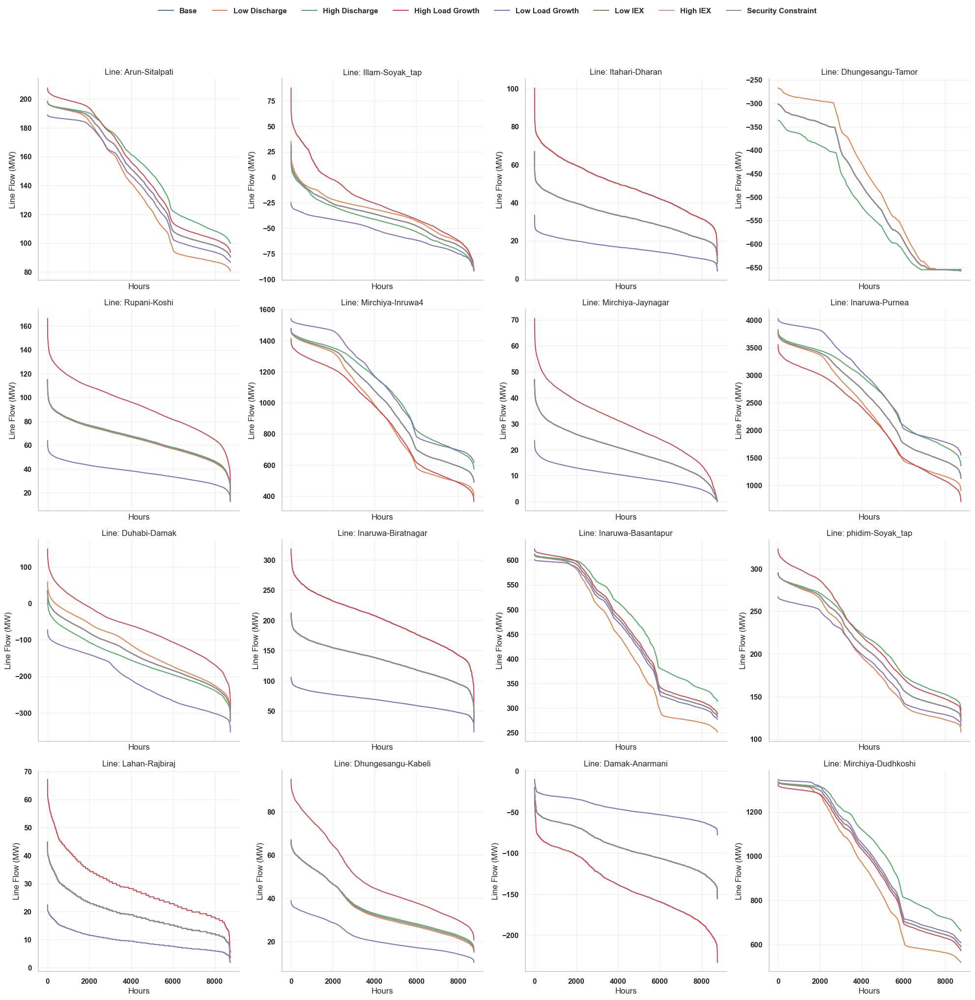

In [151]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Sample target LINES instead of buses
all_lines = solve_Scenarios['Base'].lines.index.tolist()
TARGET_LINES = pd.Series(all_lines).sample(16, random_state=42).tolist()

fig, axes = plt.subplots(4, 4, figsize=(20, 20), sharex=True)
axes = axes.flatten()

for i, line in enumerate(TARGET_LINES):
    ax = axes[i]

    for sen in scenarios:
        network = solve_Scenarios[sen]

        if line not in network.lines_t.p0.columns:
            continue

        p0 = network.lines_t.p0[line]

        # duration curve: sort descending, reset index for plotting
        duration_curve = p0.sort_values(ascending=False).reset_index(drop=True)

        ax.plot(duration_curve.index, duration_curve.values, label=sen)
    ax.grid(True, alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_title(f"Line: {line}")
    ax.set_xlabel("Hours")
    ax.set_ylabel("Line Flow (MW)")
    

# single shared legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=len(scenarios), bbox_to_anchor=(0.5, 1.02))

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("Images/Transmission_Loading_Duration.pdf", dpi=300, bbox_inches='tight')
plt.show()

Base
count    8760.000000
mean        7.190304
std         8.185192
min      -662.776228
25%         4.804959
50%         6.250775
75%         9.204294
max        18.469084
Name: Sitalpati_220, dtype: float64
Low Discharge
count    8760.000000
mean        7.190304
std         8.185192
min      -662.776228
25%         4.804959
50%         6.250775
75%         9.204294
max        18.469084
Name: Sitalpati_220, dtype: float64
High Discharge
count    8760.000000
mean        7.190304
std         7.070617
min      -523.240955
25%         4.804781
50%         6.249283
75%         9.204294
max        18.469084
Name: Sitalpati_220, dtype: float64
High Load Growth
count    8760.000000
mean        7.200320
std         8.159654
min      -662.776228
25%         4.804959
50%         6.250775
75%         9.204294
max        35.775134
Name: Sitalpati_220, dtype: float64
Low Load Growth
count    8760.000000
mean        7.190523
std         8.186491
min      -662.776228
25%         4.804959
50%         

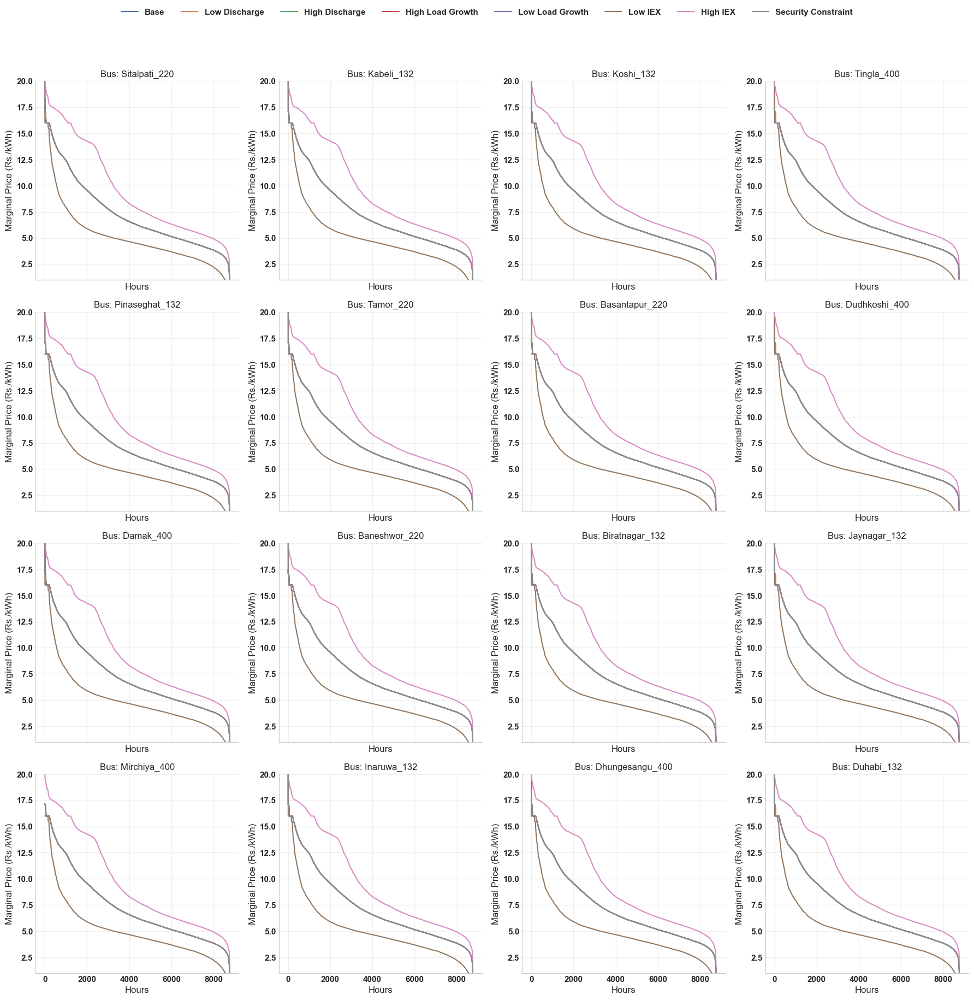

In [179]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

all_buses = solve_Scenarios['Base'].buses.index.tolist()
TARGET_BUSES = pd.Series(all_buses).sample(16, random_state=42).tolist()

fig, axes = plt.subplots(4, 4, figsize=(18, 18), sharex=True)
axes = axes.flatten()

for i, bus in enumerate(TARGET_BUSES):
    ax = axes[i]

    for sen in scenarios:
        network = solve_Scenarios[sen]

        if bus not in network.buses_t.marginal_price.columns:
            continue

        price = network.buses_t.marginal_price[bus]*Cost_Scale/1000

        # duration curve: sort descending, reset index for plotting
        duration_curve = price.sort_values(ascending=False).reset_index(drop=True)
        print(sen)
        print(duration_curve.describe())

        ax.plot(duration_curve.index, duration_curve.values, label=sen)
        #ax.set_yscale('log')
        ax.set_ylim(1,20)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    ax.set_title(f"Bus: {bus}")
    ax.set_xlabel("Hours")
    ax.set_ylabel("Marginal Price (Rs./kWh)")
    ax.grid(True, alpha=0.3)

# single shared legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=len(scenarios), bbox_to_anchor=(0.5, 1.02))

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("Images/Marginal_price.pdf", dpi=300, bbox_inches='tight')
plt.show()

### Wheeling Charge Determination 

Need to consider 30 percent regulatory asset base with 15 percent roe we cant use RoE along with the Wacc bassed annutity of the newly transmission lines

                              ARR  Energy (MWh)  Peak (MW)  \
Base                 1.724134e+10   49749798.16    6014.39   
Low Discharge        1.723323e+10   49749798.16    6014.39   
High Discharge       1.725488e+10   49749798.16    6014.39   
High Load Growth     1.766695e+10   52724697.24    6521.59   
Low Load Growth      1.694664e+10   46774899.08    5507.20   
Low IEX              1.724134e+10   49749798.16    6014.39   
High IEX             1.724134e+10   49749798.16    6014.39   
Security Constraint  1.807869e+10   49749798.16    6014.39   

                     Energy charge (Rs/kWh)  Capacity charge (Rs/MW-year)  
Base                                   0.35                    2866678.97  
Low Discharge                          0.35                    2865331.21  
High Discharge                         0.35                    2868931.36  
High Load Growth                       0.34                    2708993.73  
Low Load Growth                        0.36                  

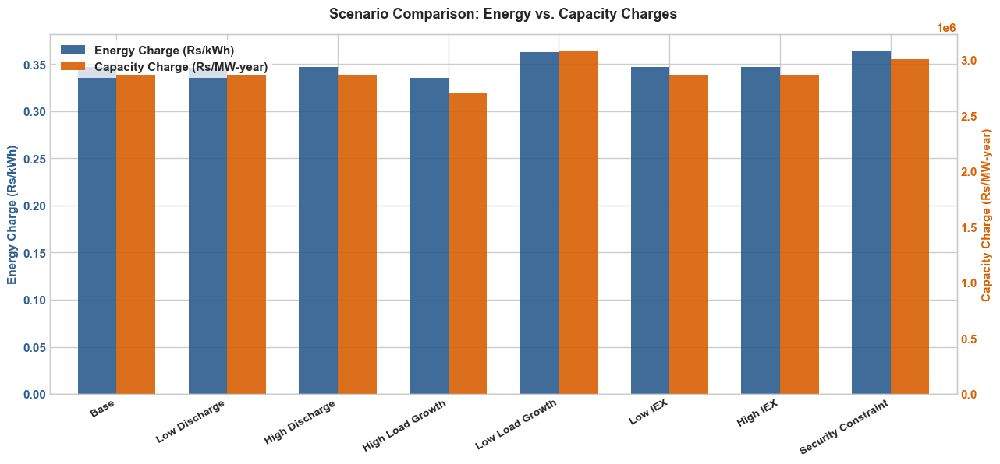

In [153]:
import pandas as pd
import matplotlib.pyplot as plt

rows = {}

for sen in scenarios:
    n = solve_Scenarios[sen]
    w = n.snapshot_weightings.objective

    # ── ARR ──────────────────────────────────────────────────────────────────
    capex = n.statistics()["Capital Expenditure"]
    base = (capex.xs("Line", level=0, drop_level=False).sum()
            + capex.xs("Transformer", level=0, drop_level=False).sum())
    ARR = (base * 1.02) * Cost_Scale

    # ── Yearly energy (MWh) and peak (MW) of system generation ──────────────
    gen = n.generators_t.p.sum(axis=1)
    energy_mwh = (gen * w).sum()
    peak_mw = gen.max()

    rows[sen] = {
        "ARR": ARR,
        "Energy (MWh)": energy_mwh,
        "Peak (MW)": peak_mw,
        "Energy charge (Rs/kWh)": ARR / (energy_mwh * 1000),
        "Capacity charge (Rs/MW-year)": ARR / peak_mw,
    }

result = pd.DataFrame(rows).T
print(result.round(2))

# ── Beautiful Single Plot (Dual-Axis) ────────────────────────────────────────
# Set a clean modern style
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig, ax1 = plt.subplots(figsize=(15, 6))

# Colors and width settings
color_energy = "#2b5c8f"    # Deep Blue
color_capacity = "#d95f02"  # Vibrant Orange
width = 0.35
x = range(len(result))

# Primary Axis: Energy charge (Rs/kWh)
bars1 = ax1.bar(
    [p - width/2 for p in x], 
    result["Energy charge (Rs/kWh)"], 
    width=width, 
    color=color_energy, 
    label="Energy Charge (Rs/kWh)",
    alpha=0.9,
    edgecolor="none"
)
ax1.set_ylabel("Energy Charge (Rs/kWh)", color=color_energy, fontsize=11, fontweight="bold")
ax1.tick_params(axis="y", labelcolor=color_energy)
ax1.set_xticks(list(x))
ax1.set_xticklabels(result.index, rotation=30, ha="right", fontsize=10)

# Secondary Axis: Capacity charge (Rs/MW-year)
ax2 = ax1.twinx()
bars2 = ax2.bar(
    [p + width/2 for p in x], 
    result["Capacity charge (Rs/MW-year)"], 
    width=width, 
    color=color_capacity, 
    label="Capacity Charge (Rs/MW-year)",
    alpha=0.9,
    edgecolor="none"
)
ax2.set_ylabel("Capacity Charge (Rs/MW-year)", color=color_capacity, fontsize=11, fontweight="bold")
ax2.tick_params(axis="y", labelcolor=color_capacity)
ax2.grid(False)  # Turn off grid for secondary axis to avoid clutter

# Title and Layout adjustments
plt.title("Scenario Comparison: Energy vs. Capacity Charges", fontsize=13, fontweight="bold", pad=15)

# Combined Legend
bars = [bars1, bars2]
labels = [b.get_label() for b in bars]
ax1.legend(bars, labels, loc="upper left", frameon=True, facecolor="white", edgecolor="none")

ax1.set_xlim(-0.6, len(result) - 0.4)
plt.savefig("Images/wheeling_yearly_charge.pdf", dpi=300, bbox_inches='tight')
plt.show()

Cost recovery split: 100% capacity / 100% energy

Energy Charge (Rs/kWh):
                     Wet Season  Dry Season
Base                   0.245137    0.400494
Low Discharge          0.251658    0.453517
High Discharge         0.239003    0.358560
High Load Growth       0.250609    0.405856
Low Load Growth        0.237471    0.392341
Low IEX                0.245137    0.400494
High IEX               0.245137    0.400494
Security Constraint    0.257042    0.419945

Capacity Charge (Rs/MW-year, based on peak system generation):
                       Wet Season    Dry Season
Base                 2.866679e+06  2.926425e+06
Low Discharge        2.865331e+06  2.925049e+06
High Discharge       2.868931e+06  2.928724e+06
High Load Growth     2.708994e+06  2.787726e+06
Low Load Growth      3.077180e+06  3.111872e+06
Low IEX              2.866679e+06  2.926425e+06
High IEX             2.866679e+06  2.926425e+06
Security Constraint  3.005903e+06  3.068551e+06


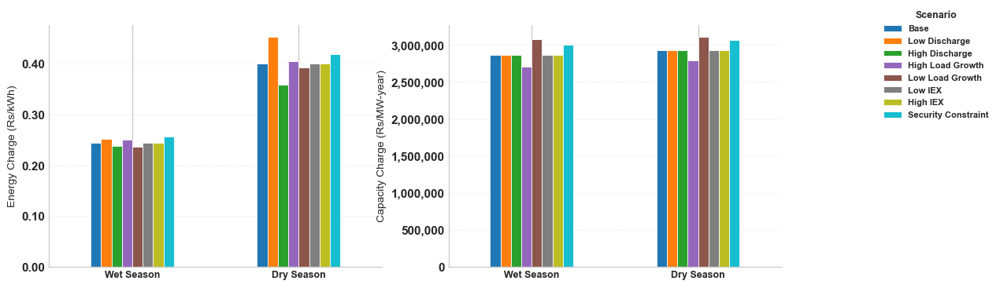

In [154]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ── Define seasons (adjust months to match your local hydrology) ────────────
wet_months = [6, 7, 8, 9, 10, 11]
dry_months = [12, 1, 2, 3, 4, 5]

# ── Cost recovery split ───────────────────────────────────────────────────────
capacity_share = 1   # 50% of ARR recovered via capacity (Rs/MW) charge
energy_share   = 1   # 50% of ARR recovered via energy (Rs/kWh) charge

# ── Compute wet/dry wheeling rates (Rs/kWh and Rs/MW-year) for each scenario ─
rates_mwh = {}
rates_mw = {}

for sen in scenarios:
    network = solve_Scenarios[sen]
    lines_t = network.lines_t
    generators_t = network.generators_t.p  # actual dispatch per generator
    snapshot_weightings = network.snapshot_weightings.objective

    # ── ARR (Annual Revenue Requirement) — includes Line + Transformer capex ─
    stats = network.statistics()
    line_capex = stats["Capital Expenditure"].xs("Line", level=0, drop_level=False).sum()
    subs_capex = stats["Capital Expenditure"].xs("Transformer", level=0, drop_level=False).sum()
    total_capex_opex = (line_capex + subs_capex) * 1.02 # 10% of capex as opex
    ARR_total = total_capex_opex * Cost_Scale

    # ── Split ARR into capacity-recovered and energy-recovered portions ─────
    ARR_capacity = ARR_total * capacity_share
    ARR_energy   = ARR_total * energy_share

    # ── Energy wheeled, split by season (for Rs/kWh) ─────────────────────────
    total_line_flow = lines_t.p0.abs().multiply(snapshot_weightings, axis=0)
    snapshot_months = total_line_flow.index.month

    energy_wet = total_line_flow.loc[snapshot_months.isin(wet_months)].sum().sum()
    energy_dry = total_line_flow.loc[snapshot_months.isin(dry_months)].sum().sum()

    rate_wet_mwh = ARR_energy / (energy_wet * 1000)   # Rs/kWh
    rate_dry_mwh = ARR_energy / (energy_dry * 1000)   # Rs/kWh

    rates_mwh[sen] = {"Wet Season": rate_wet_mwh, "Dry Season": rate_dry_mwh}

    # ── System-wide total generator dispatch (sum across all generators) ────
    total_generation = generators_t.sum(axis=1)  # MW at each snapshot
    gen_months = total_generation.index.month

    peak_load_wet = total_generation.loc[gen_months.isin(wet_months)].max()
    peak_load_dry = total_generation.loc[gen_months.isin(dry_months)].max()

    # Rs/MW-year (capacity portion of ARR divided by peak generation dispatch)
    rate_wet_mw = ARR_capacity / peak_load_wet
    rate_dry_mw = ARR_capacity / peak_load_dry

    rates_mw[sen] = {"Wet Season": rate_wet_mw, "Dry Season": rate_dry_mw}

rate_mwh_df = pd.DataFrame(rates_mwh).T
rate_mw_df = pd.DataFrame(rates_mw).T

print(f"Cost recovery split: {capacity_share:.0%} capacity / {energy_share:.0%} energy\n")
print("Energy Charge (Rs/kWh):")
print(rate_mwh_df)
print("\nCapacity Charge (Rs/MW-year, based on peak system generation):")
print(rate_mw_df)

# ── Plot: side by side ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# --- Subplot 1: Rs/kWh (energy portion) ---
ax1 = axes[0]
rate_mwh_df.T.plot(kind="bar", ax=ax1, colormap="tab10", edgecolor="white", linewidth=0.6, legend=False)
ax1.set_ylabel("Energy Charge (Rs/kWh)", fontsize=10)
ax1.set_xlabel("")
ax1.set_xticklabels(rate_mwh_df.columns, rotation=0, fontsize=9)
ax1.grid(axis="y", linestyle=":", linewidth=0.6, alpha=0.6)
ax1.spines[["top", "right"]].set_visible(False)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.2f}"))
#ax1.set_title(f"{energy_share:.0%} of ARR via Energy", fontsize=11)

# --- Subplot 2: Rs/MW-year (capacity portion) ---
ax2 = axes[1]
rate_mw_df.T.plot(kind="bar", ax=ax2, colormap="tab10", edgecolor="white", linewidth=0.6, legend=False)
ax2.set_ylabel("Capacity Charge (Rs/MW-year)", fontsize=10)
ax2.set_xlabel("")
ax2.set_xticklabels(rate_mw_df.columns, rotation=0, fontsize=9)
ax2.grid(axis="y", linestyle=":", linewidth=0.6, alpha=0.6)
ax2.spines[["top", "right"]].set_visible(False)
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
#ax2.set_title(f"{capacity_share:.0%} of ARR via Capacity", fontsize=11)

# --- Shared legend outside, near the figure ─────────────────────────────────
handles, labels = ax2.get_legend_handles_labels()
fig.legend(handles, labels, title="Scenario", fontsize=8, title_fontsize=9,
           loc="upper left", bbox_to_anchor=(1.0, 0.95))

plt.savefig("Images/wheeling_charge_seasonal.pdf", dpi=300, bbox_inches='tight')
plt.show()

### Network Plot

Line 'Inaruwa-Purnea' peaks at 3780.07 MW on snapshot 2020-09-07 08:00:00
Line 'Inaruwa-Purnea' peaks at 3780.07 MW at snapshot #6008


INFO:pypsa.network.power_flow:Performing linear load-flow on AC sub-network <pypsa.networks.SubNetwork object at 0xd8804af90> for snapshot(s) DatetimeIndex(['2020-09-07 08:00:00'], dtype='datetime64[us]', name='snapshot', freq=None)


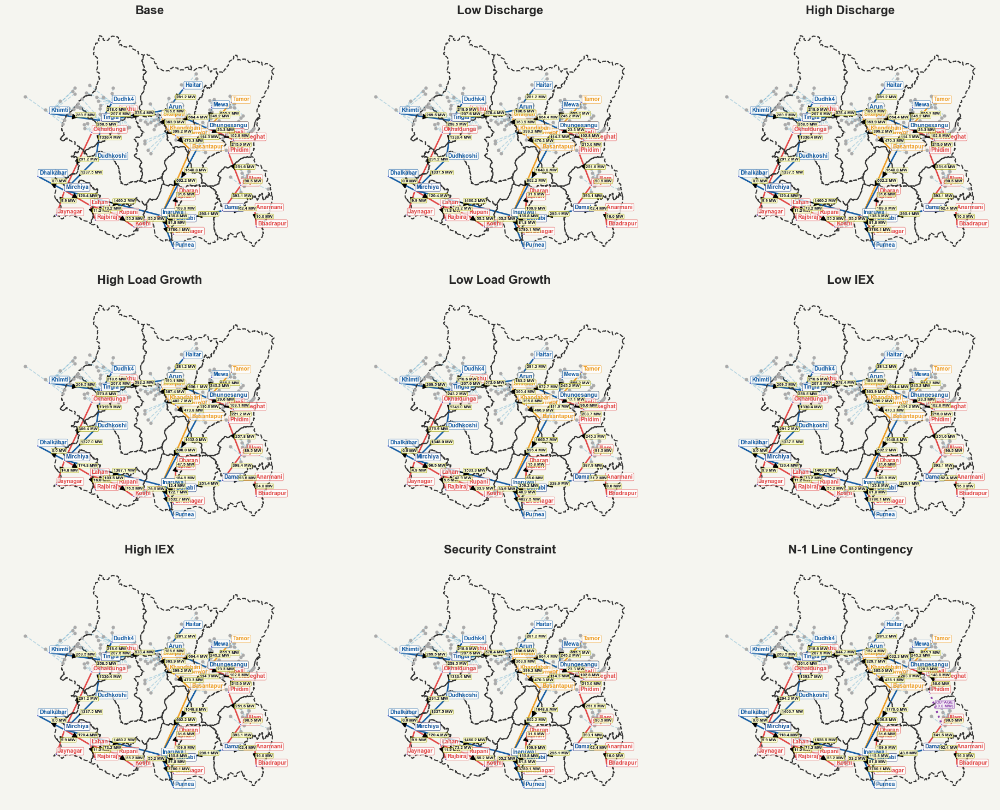

In [155]:
from Network_Plot import plot_network_flow
import numpy as np

n = len(scenarios)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(20, 10 * nrows / 2))
fig.patch.set_facecolor('#f5f5f0')
axes_flat = axes.flatten()

max_snapshot_number = get_max_snapshot(solve_Scenarios['Base'])

for i, sen in enumerate(scenarios):
    network = solve_Scenarios[sen]
    ax = axes_flat[i]
    plot_network_flow(network, snapshot=max_snapshot_number, ax=ax, show_gen_labels=False, show_gen_flow_arrows=False,legend=False)
    ax.set_title(sen, fontsize=16, fontweight="bold")

for j in range(n, len(axes_flat)):
    axes_flat[j].axis("off")

#for contingency plot
ax = axes_flat[-1]
plot_network_flow(base_n,snapshot=max_snapshot_number,branch_outages = ['phidim-Soyak_tap'],ax=ax,show_gen_labels=False, show_gen_flow_arrows=False,legend=False)
ax.set_title('N-1 Line Contingency', fontsize=16, fontweight="bold")

plt.tight_layout()
plt.savefig("Images/Maps_Scenarios.pdf", dpi=300, bbox_inches='tight')
plt.show()

[Base] Snapshot: 2020-10-02 22:00:00 | Overloaded/Critical: 8 | Most loaded: Illam-Damak (203.3%)
[Low Discharge] Snapshot: 2020-10-02 22:00:00 | Overloaded/Critical: 8 | Most loaded: Illam-Damak (200.3%)
[High Discharge] Snapshot: 2020-10-02 22:00:00 | Overloaded/Critical: 8 | Most loaded: Illam-Damak (206.2%)
[High Load Growth] Snapshot: 2020-08-21 00:00:00 | Overloaded/Critical: 12 | Most loaded: Mirchiya-Lahan (225.3%)
[Low Load Growth] Snapshot: 2020-08-19 15:00:00 | Overloaded/Critical: 7 | Most loaded: Illam-Damak (197.5%)
[Low IEX] Snapshot: 2020-10-02 22:00:00 | Overloaded/Critical: 8 | Most loaded: Illam-Damak (203.3%)
[High IEX] Snapshot: 2020-10-02 22:00:00 | Overloaded/Critical: 8 | Most loaded: Illam-Damak (203.3%)
[Security Constraint] Snapshot: 2020-10-02 22:00:00 | Overloaded/Critical: 8 | Most loaded: Illam-Damak (203.3%)


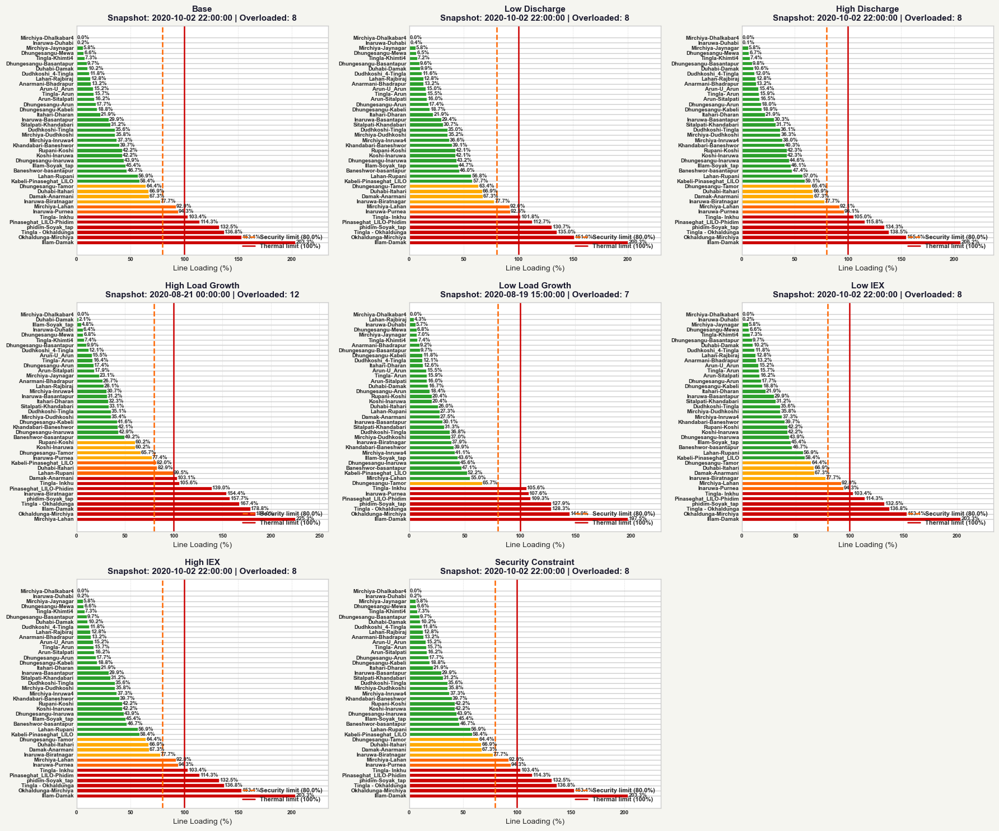

In [156]:
n = len(scenarios)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(18, 5 * nrows))
fig.patch.set_facecolor('#f5f5f0')
axes_flat = axes.flatten()

all_loading_dfs = {}
for i, sen in enumerate(scenarios):
    network = solve_Scenarios[sen]
    df = check_line_loading(network, snapshot=None, limit_pct=80.0, ax=axes_flat[i], title_prefix=sen)
    all_loading_dfs[sen] = df

for j in range(n, len(axes_flat)):
    axes_flat[j].axis("off")

plt.tight_layout()
plt.show()

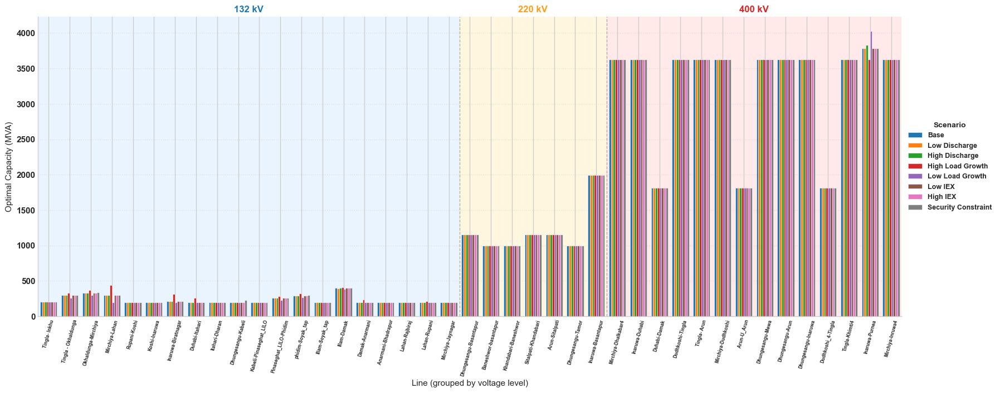

In [157]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd

# ── Collect optimal line capacity for each scenario ──────────────────────────
line_data = pd.DataFrame({
    sen: solve_Scenarios[sen].lines.s_nom_opt
    for sen in scenarios
})
v_nom = solve_Scenarios[scenarios[0]].lines['v_nom']
voltage_levels = [132, 220, 400]

# ── Order lines by voltage level, keep grouping info ─────────────────────────
ordered_lines = []
group_bounds = []  # (start_idx, end_idx, kv)
idx = 0
for kv in voltage_levels:
    lines_kv = v_nom[v_nom == kv].index
    lines_kv = line_data.index.intersection(lines_kv)
    n = len(lines_kv)
    if n == 0:
        continue
    ordered_lines.extend(lines_kv)
    group_bounds.append((idx, idx + n, kv))
    idx += n

df = line_data.loc[ordered_lines]

# ── Plot setup ────────────────────────────────────────────────────────────────
n_lines = len(df)
n_scen = len(scenarios)
x = np.arange(n_lines)
bar_width = 0.8 / n_scen

fig, ax = plt.subplots(figsize=(20, 7))

# Background shading per voltage band
kv_colors_bg = {132: "#eaf4ff", 220: "#fff6e0", 400: "#ffe9e9"}
kv_colors_line = {132: "#1f77b4", 220: "#ff9f1c", 400: "#d62728"}

for start, end, kv in group_bounds:
    ax.axvspan(start - 0.5, end - 0.5, color=kv_colors_bg.get(kv, "#eeeeee"), zorder=0)
    # vertical separator
    if start != 0:
        ax.axvline(start - 0.5, color="grey", linestyle="--", linewidth=1, alpha=0.6, zorder=1)
    # voltage label centered in its band
    mid = (start + end - 1) / 2
    #ax.text(mid, ax.get_ylim()[1], f"{kv} kV",
    #         ha="center", va="bottom", fontsize=12, fontweight="bold",
    #         color=kv_colors_line.get(kv, "black"))

# Grouped bars (scenario = color), positioned line by line
colors = plt.cm.tab10.colors
for i, sen in enumerate(scenarios):
    offset = (i - n_scen / 2) * bar_width + bar_width / 2
    ax.bar(x + offset, df[sen].values, width=bar_width,
           label=sen, color=colors[i % len(colors)],
           edgecolor="white", linewidth=0.4, zorder=2)

# ── Styling ───────────────────────────────────────────────────────────────────
ax.set_xticks(x)
ax.set_xticklabels(df.index, rotation=75, fontsize=6)
ax.set_ylabel("Optimal Capacity (MVA)", fontsize=11)
ax.set_xlabel("Line (grouped by voltage level)", fontsize=11)

ax.grid(axis="y", linestyle=":", alpha=0.5, zorder=0)
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(-0.5, n_lines - 0.5)

# Re-fetch ylim after plotting and redo top labels properly (since axvspan used pre-plot ylim)
ymax = ax.get_ylim()[1]
for start, end, kv in group_bounds:
    mid = (start + end - 1) / 2
    ax.text(mid, ymax * 1.01, f"{kv} kV", ha="center", va="bottom",
            fontsize=12, fontweight="bold", color=kv_colors_line.get(kv, "black"))

ax.legend(title="Scenario", fontsize=9, title_fontsize=10,
          loc="center left", bbox_to_anchor=(1.0, 0.5))

plt.savefig("Images/line_opt_capacity.pdf", dpi=300, bbox_inches='tight')
plt.show()

In [158]:
base_n.statistics()

Optimal Capacity  Installed Capacity  \
Generator   Dhalkebar Interconnection        1000.00000          1000.00000   
            Hydro                            4318.01200          4318.01200   
            Khimti Interconnection           2000.00000          2000.00000   
            Purnea Grid                      5000.00000          5000.00000   
Line        AC                              58218.19442         57702.23342   
Load        Internal Load                       0.00000             0.00000   
            Purnea Export                       0.00000             0.00000   
Transformer -                                3675.57330          1805.00000   

                                             Supply    Withdrawal  \
Generator   Dhalkebar Interconnection  0.000000e+00  0.000000e+00   
            Hydro                      2.801408e+07  0.000000e+00   
            Khimti Interconnection     0.000000e+00  0.000000e+00   
            Purnea Grid                2.173571e+07  0.000000e+00   
Line        AC                         1.966778e+07  9.371591e+07   
Load        Internal Load              0.000000e+00  5.949798e+06   
            Purnea Export              0.000000e+00  4.380000e+07   
Transformer -                          1.826358e+07  2.609077e+06   

                                       Energy Balance  Transmission  \
Generator   Dhalkebar Interconnection    0.000000e+00  0.000000e+00   
            Hydro                        2.801408e+07  0.000000e+00   
            Khimti Interconnection       0.000000e+00  0.000000e+00   
            Purnea Grid                  2.173571e+07  0.000000e+00   
Line        AC                          -7.404813e+07  7.404813e+07   
Load        Internal Load               -5.949798e+06  0.000000e+00   
            Purnea Export               -4.380000e+07  0.000000e+00   
Transformer -                            1.565451e+07 -1.565451e+07   

                                       Capacity Factor   Curtailment  \
Generator   Dhalkebar Interconnection         0.000000  8.760000e+06   
            Hydro                             0.740608  9.811701e+06   
            Khimti Interconnection            0.000000  1.752000e+07   
            Purnea Grid                       0.496249  2.206429e+07   
Line        AC                                0.222325  0.000000e+00   
Load        Internal Load                          NaN  0.000000e+00   
            Purnea Export                          NaN  0.000000e+00   
Transformer -                                 0.648259  0.000000e+00   

                                       Capital Expenditure  \
Generator   Dhalkebar Interconnection              0.00000   
            Hydro                              80449.95820   
            Khimti Interconnection                 0.00000   
            Purnea Grid                            0.00000   
Line        AC                                 13431.82695   
Load        Internal Load                          0.00000   
            Purnea Export                          0.00000   
Transformer -                                   3206.66475   

                                       Operational Expenditure       Revenue  \
Generator   Dhalkebar Interconnection                  0.00000       0.00000   
            Hydro                                      0.00000  192744.08083   
            Khimti Interconnection                     0.00000       0.00000   
            Purnea Grid                           162207.71502  162207.71502   
Line        AC                                         0.00000 -526306.31746   
Load        Internal Load                              0.00000  -44977.09881   
            Purnea Export                              0.00000 -319818.54758   
Transformer -                                          0.00000  110384.78288   

                                       Market Value  
Generator   Dhalkebar Interconnection           NaN  
            Hydro           

                     Hydro Generator    AC Line  Transformer
Base                       80.449958  13.619438     3.283833
Low Discharge              80.449958  13.611063     3.284261
High Discharge             80.449958  13.631572     3.284980
High Load Growth           80.449958  13.864723     3.455815
Low Load Growth            80.449958  13.466921     3.147429
Low IEX                    80.449958  13.619438     3.283833
High IEX                   80.449958  13.619438     3.283833
Security Constraint        80.449958  13.642903     4.081300


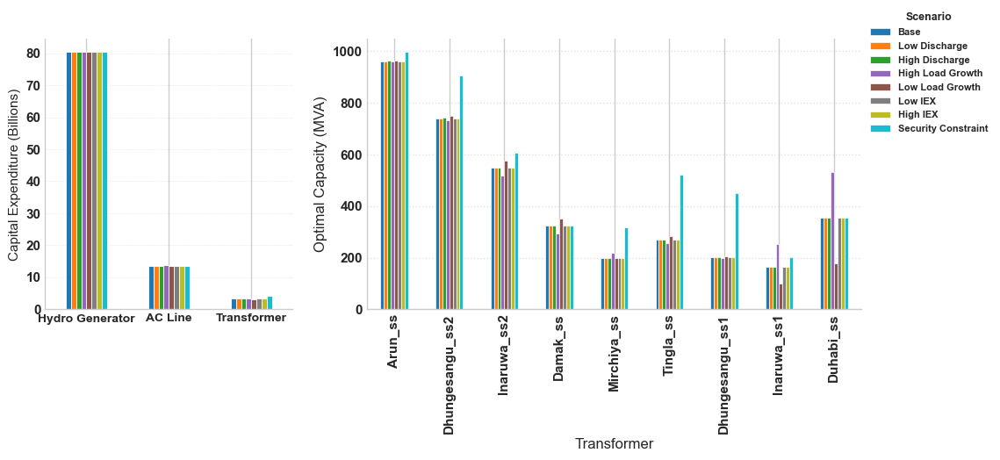

In [170]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ── Define which (component, carrier) pairs to pull for CAPEX ───────────────
capex_targets = {
    "Hydro Generator": ("Generator", "Hydro"),
    "AC Line":         ("Line", "AC"),
    "Transformer":     ("Transformer", "-"),   # adjust carrier name if different
}

# ── Collect Capital Expenditure for each scenario ────────────────────────────
capex_df = pd.DataFrame(index=scenarios)
for label, (component, carrier) in capex_targets.items():
    values = []
    for sen in scenarios:
        stats = solve_Scenarios[sen].statistics()
        try:
            val = stats["Capital Expenditure"].loc[(component, carrier)]/1000 #billions
        except KeyError:
            val = np.nan
        values.append(val)
    capex_df[label] = values

print(capex_df)

# ── Collect optimal transformer MVA for each scenario ────────────────────────
transformer_data = pd.DataFrame({
    sen: solve_Scenarios[sen].transformers.s_nom_opt
    for sen in scenarios
})

# ── Combined Plot ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 2]})

# --- Subplot 1: CAPEX ---
ax1 = axes[0]
capex_df.T.plot(kind="bar", ax=ax1, colormap="tab10", edgecolor="white", linewidth=0.6, legend=False)
ax1.set_ylabel("Capital Expenditure (Billions)", fontsize=11)
ax1.set_xlabel("")
ax1.set_xticklabels(capex_df.columns, rotation=0, fontsize=10)
ax1.grid(axis="y", linestyle=":", linewidth=0.6, alpha=0.6)
ax1.spines[["top", "right"]].set_visible(False)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))


# --- Subplot 2: Transformer capacities ---
ax2 = axes[1]
transformer_data.plot(kind="bar", ax=ax2, colormap="tab10", edgecolor="white", linewidth=0.5, legend=False)
ax2.set_xlabel("Transformer")
ax2.set_ylabel("Optimal Capacity (MVA)")
ax2.grid(axis="y", linestyle=":", alpha=0.6)
ax2.spines[["top", "right"]].set_visible(False)

# ax2.tick_params(axis="x", rotation=45)

# --- Shared legend ---
handles, labels = ax2.get_legend_handles_labels()
fig.legend(handles, labels, title="Scenario", fontsize=8, title_fontsize=9,
           loc="upper left", bbox_to_anchor=(0.9, 0.98))

plt.savefig("Images/Investment_Sizes.pdf", dpi=300, bbox_inches='tight')
plt.show()

In [160]:
import pandas as pd
import numpy as np

def diagnose_lmp(network):

    lmp   = network.buses_t.marginal_price*1000000
    p0    = network.lines_t.p0
    v_nom = network.buses['v_nom']
   

    # ── Helpers to safely sum static + dynamic components ─────────
    def avg_gen(gens):
        if not len(gens):
            return 0
        dynamic = [g for g in gens if g in network.generators_t.p.columns]
        static  = [g for g in gens if g not in network.generators_t.p.columns]
        d = network.generators_t.p[dynamic].sum(axis=1).mean() if dynamic else 0
        s = network.generators.loc[static, 'p_nom'].sum()       if static  else 0
        return d + s

    def avg_load(loads):
        if not len(loads):
            return 0
        dynamic = [l for l in loads if l in network.loads_t.p_set.columns]
        static  = [l for l in loads if l not in network.loads_t.p_set.columns]
        d = network.loads_t.p_set[dynamic].sum(axis=1).mean()   if dynamic else 0
        s = network.loads.loc[static, 'p_set'].sum()             if static  else 0
        return d + s

    # ─────────────────────────────────────────────────────────────
    # 1. LMP SUMMARY PER BUS
    # ─────────────────────────────────────────────────────────────
    lmp_stats = pd.DataFrame({
        'v_nom'        : v_nom,
        'mean'         : lmp.mean(),
        'min'          : lmp.min(),
        'max'          : lmp.max(),
        'std'          : lmp.std(),
        'negative_hrs' : (lmp < 0).sum(),
        'zero_hrs'     : (lmp == 0).sum(),
    }).sort_values('mean')

    print("=" * 75)
    print("  LMP SUMMARY BY BUS")
    print("=" * 75)
    print(f"{'Bus':<30} {'kV':>5} {'Mean':>10} {'Min':>10} "
          f"{'Max':>10} {'Std':>8} {'Neg hrs':>8} {'Zero hrs':>9}")
    print("-" * 75)
    for bus, row in lmp_stats.iterrows():
        flag = ""
        if row['mean'] < 0:            flag = "  ← stranded surplus"
        elif row['negative_hrs'] > 0:  flag = "  ← intermittent surplus"
        elif row['std'] < 1:           flag = "  ← slack / reference bus"
        print(f"{bus:<30} {int(row['v_nom']):>5} "
              f"{row['mean']:>10,.1f} {row['min']:>10,.1f} "
              f"{row['max']:>10,.1f} {row['std']:>8,.1f} "
              f"{int(row['negative_hrs']):>8} {int(row['zero_hrs']):>9}"
              f"{flag}")

    # ─────────────────────────────────────────────────────────────
    # 2. CONGESTION RENT BY LINE
    # ─────────────────────────────────────────────────────────────
    print("\n" + "=" * 75)
    print("  CONGESTION RENT BY LINE")
    print("=" * 75)
    print(f"{'Line':<35} {'bus0':<18} {'bus1':<18} "
          f"{'Spread':>10} {'Loading%':>9} {'Status':>12}")
    print("-" * 75)

    line_stats = []
    for line in network.lines.index:
        bus0  = network.lines.loc[line, 'bus0']
        bus1  = network.lines.loc[line, 'bus1']
        s_nom = network.lines.loc[line, 's_nom']

        spread        = (lmp[bus1] - lmp[bus0]).abs().mean()
        loading_pct   = (p0[line].abs() / s_nom * 100).mean()
        congested_frac= (p0[line].abs() >= 0.99 * s_nom).mean() * 100

        status = "CONGESTED"  if congested_frac > 5  else \
                 "NEAR LIMIT" if loading_pct > 80    else "ok"

        line_stats.append({
            'line': line, 'bus0': bus0, 'bus1': bus1,
            'spread': spread, 'loading_pct': loading_pct,
            'congested_frac': congested_frac, 'status': status
        })
        print(f"{line:<35} {bus0:<18} {bus1:<18} "
              f"{spread:>10,.1f} {loading_pct:>8.1f}% {status:>12}")

    # ─────────────────────────────────────────────────────────────
    # 3. GENERATION vs LOAD vs NET EXPORT BY BUS
    # ─────────────────────────────────────────────────────────────
    print("\n" + "=" * 75)
    print("  GENERATION vs LOAD vs NET EXPORT BY BUS")
    print("=" * 75)
    print(f"{'Bus':<30} {'Gen MW':>9} {'Load MW':>9} "
          f"{'Net Export':>11} {'LMP mean':>10}")
    print("-" * 75)

    for bus in network.buses.index:
        gens  = network.generators[network.generators['bus'] == bus].index
        loads = network.loads[network.loads['bus'] == bus].index

        gen_p      = avg_gen(gens)
        load_p     = avg_load(loads)         # ← uses safe helper
        net_export = gen_p - load_p
        lmp_avg    = lmp[bus].mean()

        flag = ""
        if net_export >  50 and lmp_avg < 0:
            flag = "  ← surplus trapped"
        elif net_export < -50 and lmp_avg > 5000:
            flag = "  ← import dependent"

        print(f"{bus:<30} {gen_p:>9,.1f} {load_p:>9,.1f} "
              f"{net_export:>11,.1f} {lmp_avg:>10,.1f}{flag}")

    # ─────────────────────────────────────────────────────────────
    # 4. LMP DECOMPOSITION — ENERGY vs CONGESTION
    # ─────────────────────────────────────────────────────────────
    print("\n" + "=" * 75)
    print("  LMP DECOMPOSITION  (time-averaged)")
    print("=" * 75)

    ref_bus = lmp_stats['std'].idxmin()
    ref_lmp = lmp[ref_bus].mean()

    print(f"  Reference bus : {ref_bus}  →  {ref_lmp:,.1f} NPR/MWh\n")
    print(f"{'Bus':<30} {'Energy':>12} {'Congestion':>12} {'Total LMP':>12}")
    print("-" * 75)
    for bus in lmp_stats.index:
        total      = lmp[bus].mean()
        congestion = total - ref_lmp
        print(f"{bus:<30} {ref_lmp:>12,.1f} {congestion:>12,.1f} {total:>12,.1f}")

    # ─────────────────────────────────────────────────────────────
    # 5. INVESTMENT PRIORITY RANKING
    # ─────────────────────────────────────────────────────────────
    print("\n" + "=" * 75)
    print("  INVESTMENT PRIORITY — LINES RANKED BY CONGESTION RENT")
    print("=" * 75)
    print(f"{'Rank':<5} {'Line':<35} {'LMP Spread':>12} "
          f"{'Loading%':>10} {'Congested%':>11}")
    print("-" * 75)

    ranked = sorted(line_stats, key=lambda x: x['spread'], reverse=True)
    for i, row in enumerate(ranked, 1):
        print(f"{i:<5} {row['line']:<35} {row['spread']:>12,.1f} "
              f"{row['loading_pct']:>9.1f}% {row['congested_frac']:>10.1f}%")

    print("\n  Lines with highest LMP spread = highest value to expand first.")
    print("=" * 75)

    return pd.DataFrame(ranked)

In [161]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def compute_lmp_diagnostics(network):
    """Compute LMP diagnostics for one network. Returns a dict of DataFrames (no printing)."""
    lmp   = network.buses_t.marginal_price * 1_000_000
    p0    = network.lines_t.p0
    v_nom = network.buses['v_nom']

    def avg_gen(gens):
        if not len(gens): return 0
        dynamic = [g for g in gens if g in network.generators_t.p.columns]
        static  = [g for g in gens if g not in network.generators_t.p.columns]
        d = network.generators_t.p[dynamic].sum(axis=1).mean() if dynamic else 0
        s = network.generators.loc[static, 'p_nom'].sum() if static else 0
        return d + s

    def avg_load(loads):
        if not len(loads): return 0
        dynamic = [l for l in loads if l in network.loads_t.p_set.columns]
        static  = [l for l in loads if l not in network.loads_t.p_set.columns]
        d = network.loads_t.p_set[dynamic].sum(axis=1).mean() if dynamic else 0
        s = network.loads.loc[static, 'p_set'].sum() if static else 0
        return d + s

    # 1. LMP summary per bus
    lmp_stats = pd.DataFrame({
        'v_nom': v_nom, 'mean': lmp.mean(), 'min': lmp.min(), 'max': lmp.max(),
        'std': lmp.std(), 'negative_hrs': (lmp < 0).sum(), 'zero_hrs': (lmp == 0).sum(),
    }).sort_values('mean')

    # 2. Congestion rent by line
    line_rows = []
    for line in network.lines.index:
        bus0, bus1 = network.lines.loc[line, ['bus0', 'bus1']]
        s_nom = network.lines.loc[line, 's_nom']
        spread = (lmp[bus1] - lmp[bus0]).abs().mean()
        loading_pct = (p0[line].abs() / s_nom * 100).mean()
        congested_frac = (p0[line].abs() >= 0.99 * s_nom).mean() * 100
        status = "CONGESTED" if congested_frac > 5 else "NEAR LIMIT" if loading_pct > 80 else "ok"
        line_rows.append({'line': line, 'bus0': bus0, 'bus1': bus1, 'spread': spread,
                           'loading_pct': loading_pct, 'congested_frac': congested_frac, 'status': status})
    line_stats = pd.DataFrame(line_rows).sort_values('spread', ascending=False)

    # 3. Generation vs load vs net export by bus
    gle_rows = []
    for bus in network.buses.index:
        gens  = network.generators[network.generators['bus'] == bus].index
        loads = network.loads[network.loads['bus'] == bus].index
        gen_p, load_p = avg_gen(gens), avg_load(loads)
        gle_rows.append({'bus': bus, 'gen_MW': gen_p, 'load_MW': load_p,
                          'net_export': gen_p - load_p, 'lmp_mean': lmp[bus].mean()})
    gen_load_export = pd.DataFrame(gle_rows).set_index('bus')

    # 4. LMP decomposition (energy vs congestion)
    ref_bus = lmp_stats['std'].idxmin()
    ref_lmp = lmp[ref_bus].mean()
    decomposition = pd.DataFrame({
        'energy': ref_lmp,
        'congestion': lmp_stats['mean'] - ref_lmp,
        'total': lmp_stats['mean'],
    })

    return {
        'lmp_stats': lmp_stats,
        'line_stats': line_stats,
        'gen_load_export': gen_load_export,
        'decomposition': decomposition,
        'ref_bus': ref_bus,
    }


def plot_lmp_diagnostics(diag, scenario_name="", axes=None):
    """Plot the 4 key diagnostic panels for one scenario's diagnostics dict."""
    standalone = axes is None
    if standalone:
        fig, axes = plt.subplots(2, 2, figsize=(16, 10))
        fig.suptitle(f"LMP Diagnostics — {scenario_name}", fontsize=14, fontweight="bold")

    lmp_stats, line_stats, gle, decomp = (
        diag['lmp_stats'], diag['line_stats'], diag['gen_load_export'], diag['decomposition']
    )

    # Panel 1: LMP mean by bus (sorted)
    ax = axes[0, 0]
    colors = ['#cc0000' if m < 0 else '#2ca02c' for m in lmp_stats['mean']]
    ax.barh(lmp_stats.index, lmp_stats['mean'], color=colors, edgecolor='white')
    ax.set_title("Mean LMP by Bus (NPR/MWh)", fontsize=11, fontweight='bold')
    ax.axvline(0, color='black', lw=0.8)
    ax.tick_params(labelsize=7)

    # Panel 2: Congestion rent (spread) by line, top 10
    ax = axes[0, 1]
    top_lines = line_stats.head(10)
    bar_colors = ['#cc0000' if s == "CONGESTED" else '#ff9900' if s == "NEAR LIMIT" else '#2ca02c'
                  for s in top_lines['status']]
    ax.barh(top_lines['line'], top_lines['spread'], color=bar_colors, edgecolor='white')
    ax.set_title("Top 10 Lines by LMP Spread (Congestion Rent)", fontsize=11, fontweight='bold')
    ax.tick_params(labelsize=7)
    ax.invert_yaxis()

    # Panel 3: Net export vs LMP scatter
    ax = axes[1, 0]
    ax.scatter(gle['net_export'], gle['lmp_mean'], c=gle['lmp_mean'], cmap='RdYlGn_r', s=60, edgecolor='black')
    for bus, row in gle.iterrows():
        ax.annotate(bus, (row['net_export'], row['lmp_mean']), fontsize=6, alpha=0.7)
    ax.axvline(0, color='gray', lw=0.6, linestyle='--')
    ax.set_xlabel("Net Export (MW)", fontsize=9)
    ax.set_ylabel("Mean LMP", fontsize=9)
    ax.set_title("Net Export vs Mean LMP by Bus", fontsize=11, fontweight='bold')
    ax.tick_params(labelsize=7)

    # Panel 4: LMP decomposition (energy vs congestion), stacked bar
    ax = axes[1, 1]
    decomp_sorted = decomp.sort_values('total')
    ax.barh(decomp_sorted.index, decomp_sorted['energy'], color='#1f77b4', label='Energy component')
    ax.barh(decomp_sorted.index, decomp_sorted['congestion'], left=decomp_sorted['energy'],
            color='#ff7f0e', label='Congestion component')
    ax.set_title("LMP Decomposition: Energy vs Congestion", fontsize=11, fontweight='bold')
    ax.legend(fontsize=7, loc='lower right')
    ax.tick_params(labelsize=7)

    if standalone:
        plt.tight_layout()
        plt.show()

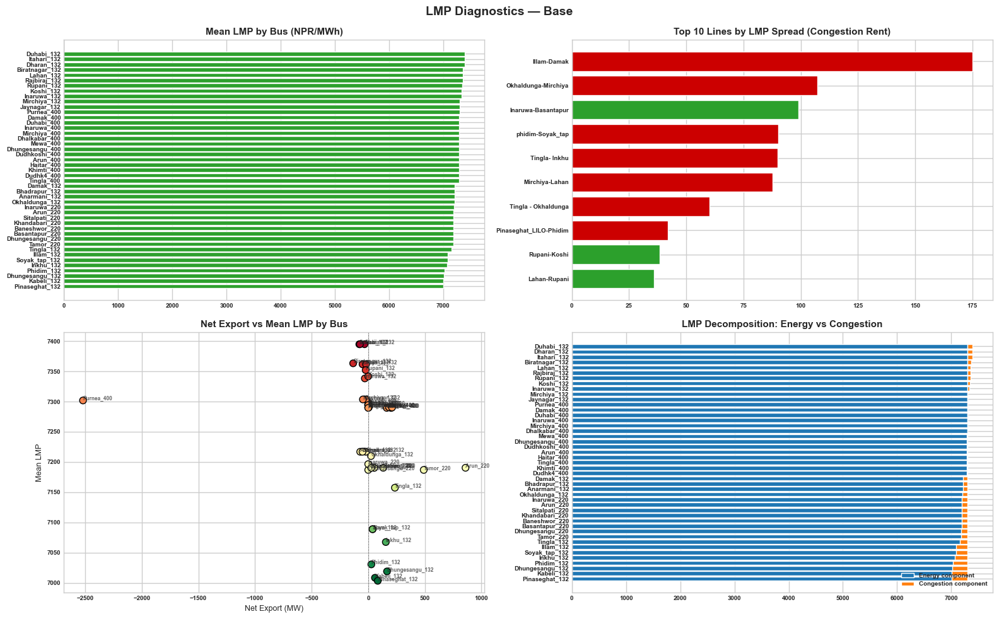

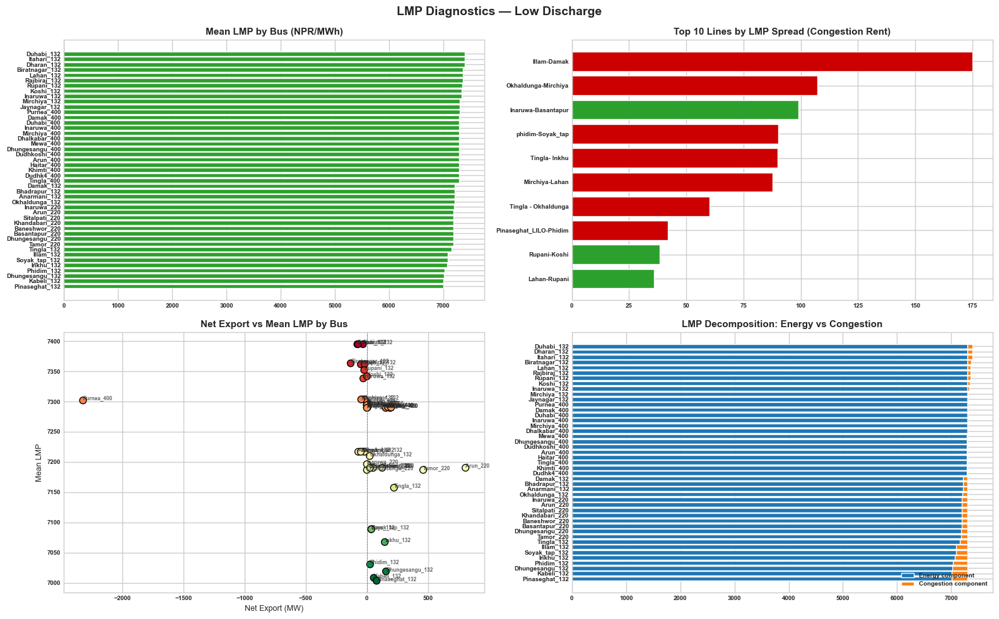

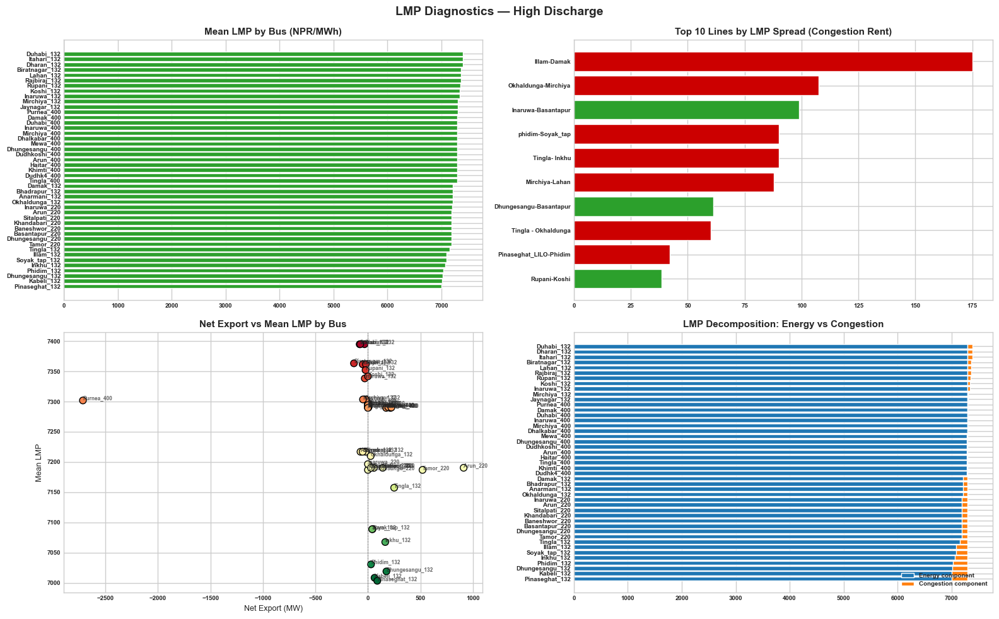

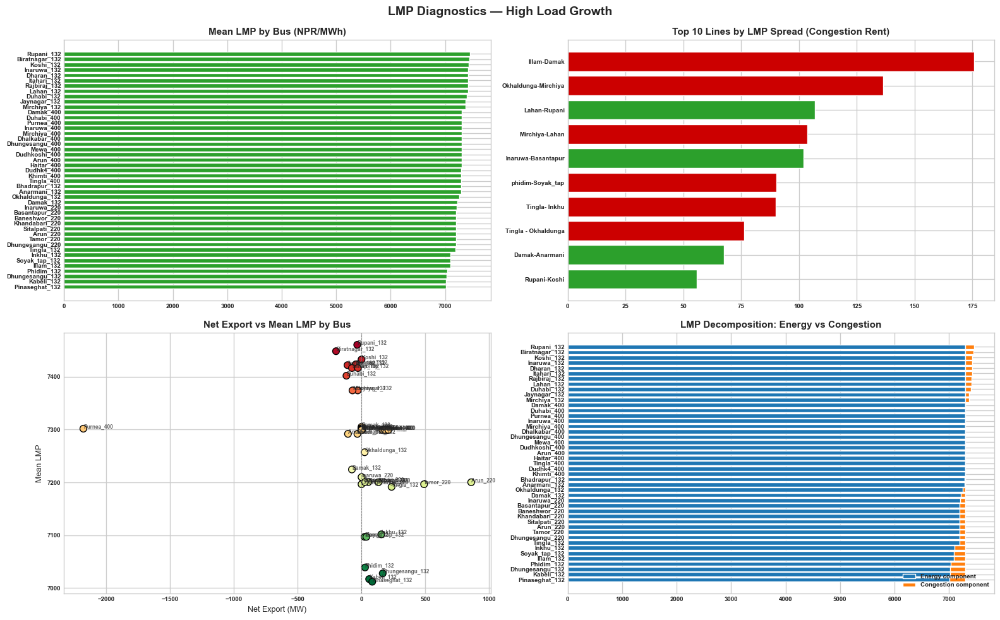

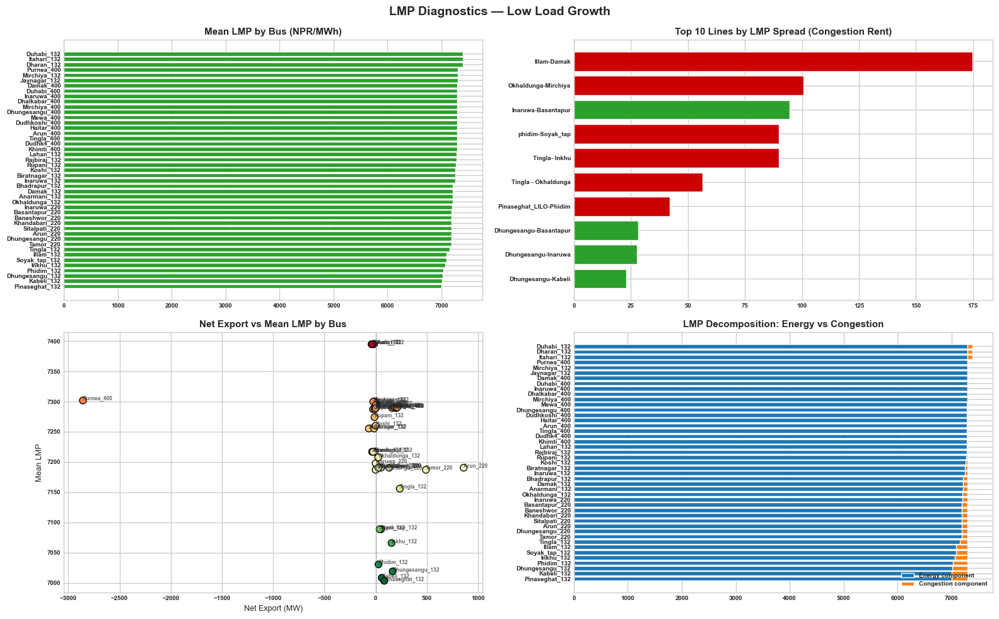

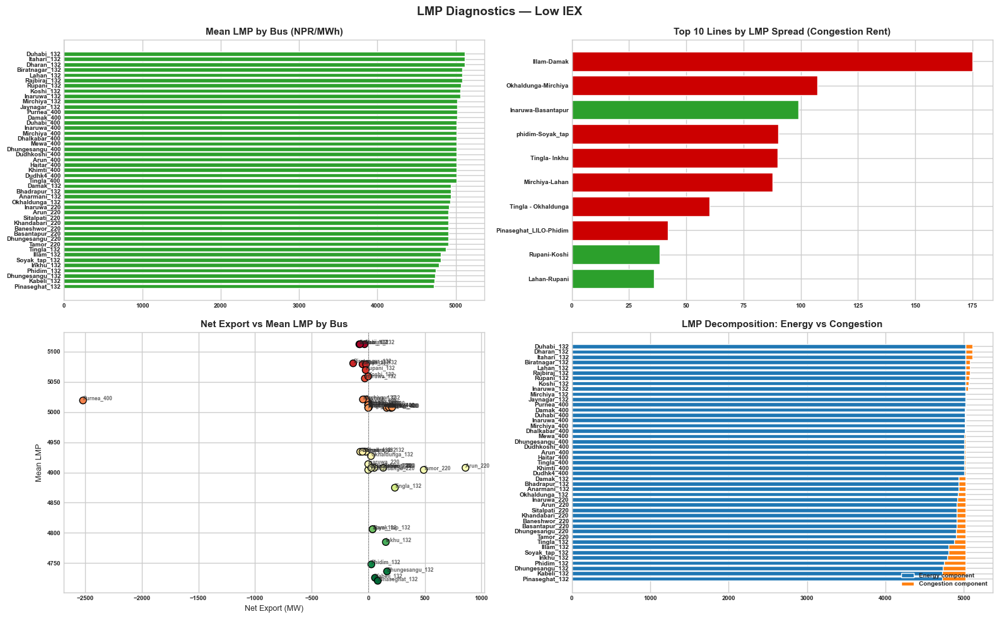

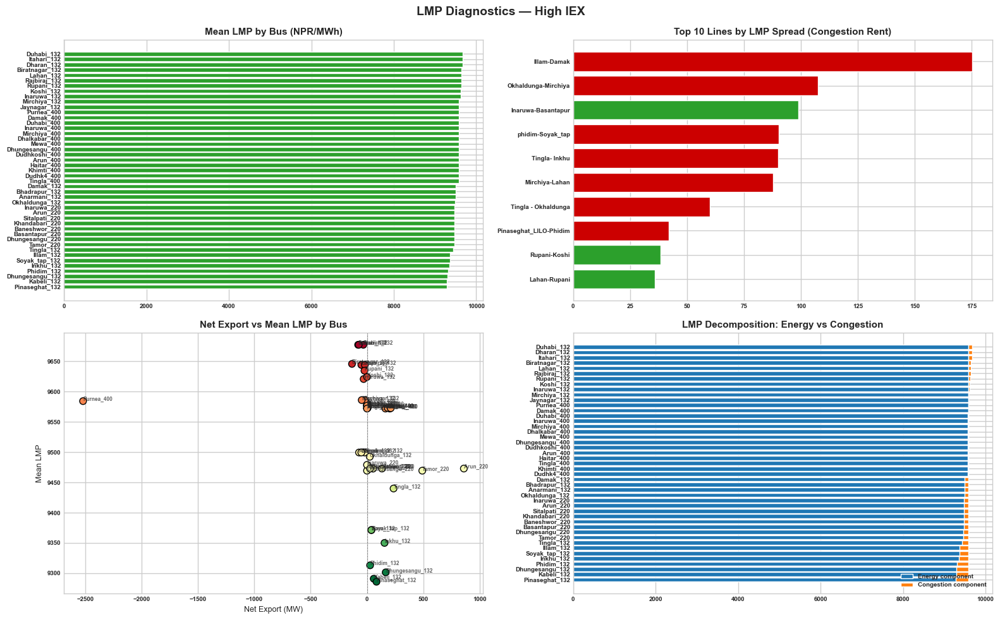

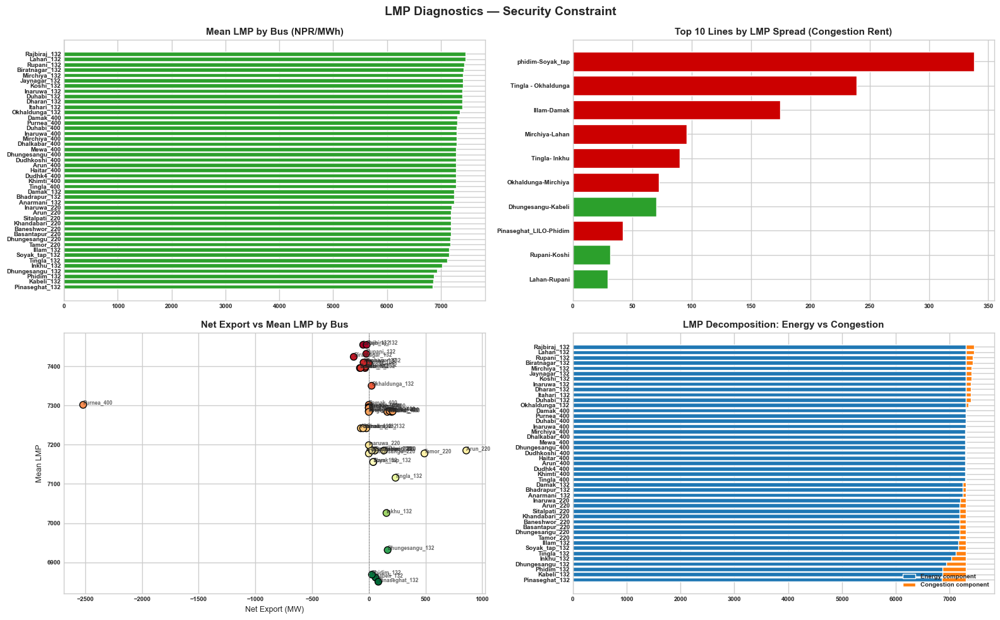

/var/folders/zk/lh41nc414yl79qyknsg_d3kr0000gn/T/ipykernel_23925/3593726444.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(diag['lmp_stats'].index, rotation=90, fontsize=7)


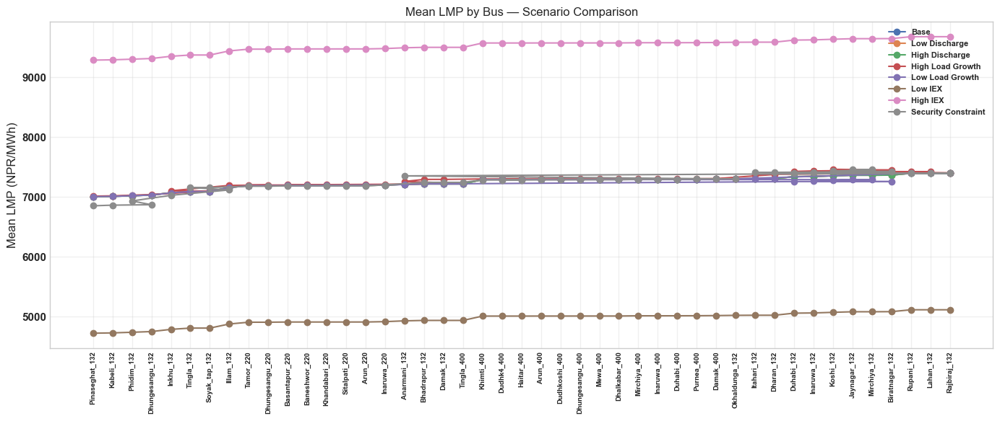

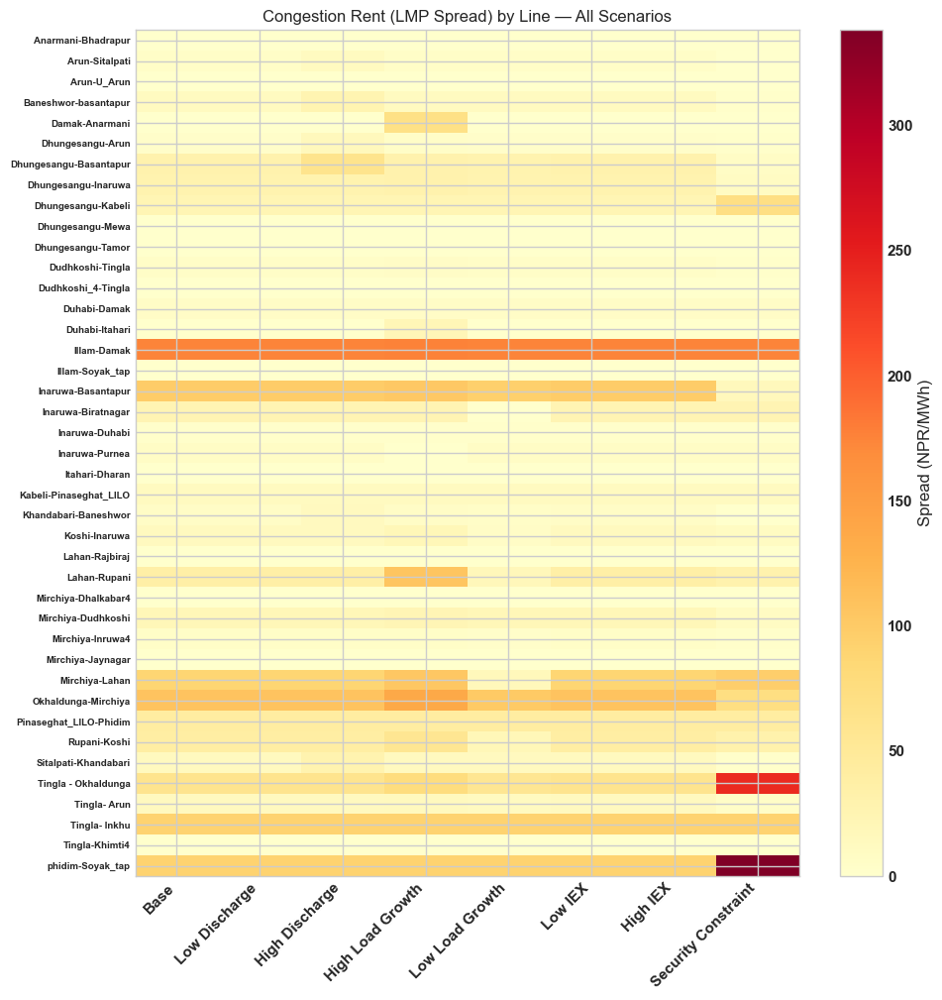

In [162]:
all_diagnostics = {}
for sen in scenarios:
    network = solve_Scenarios[sen]
    all_diagnostics[sen] = compute_lmp_diagnostics(network)

# Option A: One full 2x2 dashboard per scenario
for sen, diag in all_diagnostics.items():
    plot_lmp_diagnostics(diag, scenario_name=sen)

# Option B: Cross-scenario comparison — e.g. mean LMP by bus, all scenarios overlaid
fig, ax = plt.subplots(figsize=(14, 6))
for sen, diag in all_diagnostics.items():
    ax.plot(diag['lmp_stats'].index, diag['lmp_stats']['mean'], marker='o', label=sen)
ax.set_xticklabels(diag['lmp_stats'].index, rotation=90, fontsize=7)
ax.set_ylabel("Mean LMP (NPR/MWh)")
ax.set_title("Mean LMP by Bus — Scenario Comparison")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Option C: Congestion rent comparison — top lines across scenarios (heatmap)
import seaborn as sns  # optional, or use matplotlib imshow if seaborn unavailable
all_lines = set()
for diag in all_diagnostics.values():
    all_lines.update(diag['line_stats'].set_index('line')['spread'].index)

spread_matrix = pd.DataFrame({
    sen: diag['line_stats'].set_index('line')['spread'] for sen, diag in all_diagnostics.items()
}).fillna(0)

fig, ax = plt.subplots(figsize=(10, max(6, len(spread_matrix) * 0.25)))
im = ax.imshow(spread_matrix.values, cmap='YlOrRd', aspect='auto')
ax.set_xticks(range(len(spread_matrix.columns)))
ax.set_xticklabels(spread_matrix.columns, rotation=45, ha='right')
ax.set_yticks(range(len(spread_matrix.index)))
ax.set_yticklabels(spread_matrix.index, fontsize=7)
ax.set_title("Congestion Rent (LMP Spread) by Line — All Scenarios")
fig.colorbar(im, ax=ax, label="Spread (NPR/MWh)")
plt.tight_layout()
plt.show()